Projection Erasure v6 Clean — joint-pathway concept suppression for FLUX + SD3.5
Concept-agnostic, architecture-aware, mask-aware, with anchor ablation and scene-protected joint erasure.

In [1]:
# ============================================================================
# CELL 1: INSTALL + CONFIG
# ============================================================================

# In a notebook/Colab, uncomment these:
# !pip install "diffusers>=0.31" transformers accelerate sentencepiece protobuf --quiet
# !pip install pandas matplotlib pillow tqdm --quiet

import os, gc, json, math, re
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import torch
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_FAMILY = "sd3"  # "flux" | "sd3"
FLUX_MODEL_ID = "black-forest-labs/FLUX.1-schnell"  # or "black-forest-labs/FLUX.1-schnell"
SD3_MODEL_ID  = "stabilityai/stable-diffusion-3.5-medium"
CPU_OFFLOAD = False

if MODEL_FAMILY == "flux":
    MODEL_ID = FLUX_MODEL_ID
    N_STEPS = 4 if "schnell" in MODEL_ID.lower() else 28
    GUIDANCE = 0.0 if "schnell" in MODEL_ID.lower() else 3.5  # FLUX embedded guidance
    MAX_SEQ = 256 if "schnell" in MODEL_ID.lower() else 512
else:
    MODEL_ID = SD3_MODEL_ID
    N_STEPS = 28
    GUIDANCE = 4.5  # SD3.5 true CFG guidance
    MAX_SEQ = 256

try:
    from google.colab import drive, userdata
    from huggingface_hub import login
    drive.mount("/content/drive")
    ROOT_DIR = "/content/drive/MyDrive/FULL_v6_sd3.5-medium_clean_ProjectionErasure_"
    try:
        login(userdata.get("hf_token"))
    except Exception:
        print("⚠ no HF token found in Colab userdata")
except Exception:
    ROOT_DIR = "."

for s in ["subspaces", "figs", "eval_images", "tables"]:
    os.makedirs(os.path.join(ROOT_DIR, s), exist_ok=True)

SUB_DIR = os.path.join(ROOT_DIR, "subspaces")
FIG_DIR = os.path.join(ROOT_DIR, "figs")
EVAL_DIR = os.path.join(ROOT_DIR, "eval_images")
TAB_DIR = os.path.join(ROOT_DIR, "tables")

print(f"DEVICE={DEVICE}")
print(f"{MODEL_FAMILY=} | {MODEL_ID=} | steps={N_STEPS} | guidance={GUIDANCE} | max_seq={MAX_SEQ}")
print(f"ROOT_DIR={ROOT_DIR}")

Mounted at /content/drive
DEVICE=cuda
MODEL_FAMILY='sd3' | MODEL_ID='stabilityai/stable-diffusion-3.5-medium' | steps=28 | guidance=4.5 | max_seq=256
ROOT_DIR=/content/drive/MyDrive/FULL_v6_sd3.5-medium_clean_ProjectionErasure_


In [2]:
# ============================================================================
# CELL 2: PROMPT PAIRS + ANCHORS
# ============================================================================

IMAGENET_CLASSES = [
    "tench", "goldfish", "tiger shark", "hammerhead", "electric ray",
    "hen", "ostrich", "brambling", "goldfinch", "house finch",
    "junco", "indigo bunting", "robin", "bulbul", "jay",
    "magpie", "chickadee", "water ouzel", "kite", "bald eagle",
    "vulture", "great grey owl", "mud turtle", "box turtle", "banded gecko",
    "common iguana", "whiptail lizard", "agama", "frilled lizard", "alligator lizard",
    "green mamba", "thunder snake", "ringneck snake", "king snake", "garter snake",
    "vine snake", "trilobite", "scorpion", "black widow", "tarantula",
    "centipede", "grouse", "peacock", "quail", "partridge",
    "macaw", "lorikeet", "coucal", "bee eater", "hornbill",
]

OBJECT_CONTEXTS = [
    "a photo of {X} in a park",
    "a photo of {X} on a city street",
    "{X} in a garden",
    "{X} on a beach at sunset",
    "{X} in the snow",
    "a close-up photo of {X}",
    "{X} next to a red bench",
    "{X} near a lake",
    "{X} in a forest",
    "{X} in a living room",
    "{X} on a mountain trail",
    "a photo of {X} at night",
    "{X} in the rain",
    "{X} in a field of grass",
    "{X} beside a wooden fence",
    "{X} in front of a house",
    "{X} on a bridge",
    "{X} in an old town square",
    "{X} under a tree",
    "{X} by a river",
    "a professional photo of {X}",
    "{X} in bright sunlight",
    "{X} on a quiet road",
    "{X} near a fountain",
    "{X} in a courtyard",
]

EMPTY_SCENE_CONTEXT_PAIRS = [
    ("a photo of {X} in a park", "a photo of an empty park"),
    ("a photo of {X} on a city street", "an empty city street"),
    ("{X} in a garden", "an empty garden"),
    ("{X} on a beach at sunset", "an empty beach at sunset"),
    ("{X} in the snow", "an empty snowy scene"),
    ("a close-up photo of {X}", "a close-up photo of an empty background"),
    ("{X} next to a red bench", "an empty red bench"),
    ("{X} near a lake", "an empty lakeside scene"),
    ("{X} in a forest", "an empty forest path"),
    ("{X} in a living room", "an empty living room"),
    ("{X} on a mountain trail", "an empty mountain trail"),
    ("a photo of {X} at night", "an empty night scene"),
    ("{X} in the rain", "an empty rainy scene"),
    ("{X} in a field of grass", "an empty field of grass"),
    ("{X} beside a wooden fence", "an empty wooden fence scene"),
    ("{X} in front of a house", "the front of a house with no foreground subject"),
    ("{X} on a bridge", "an empty bridge"),
    ("{X} in an old town square", "an empty old town square"),
    ("{X} under a tree", "an empty area under a tree"),
    ("{X} by a river", "an empty riverbank"),
    ("a professional photo of {X}", "a professional photo of an empty studio setting"),
    ("{X} in bright sunlight", "an empty sunny outdoor scene"),
    ("{X} on a quiet road", "an empty quiet road"),
    ("{X} near a fountain", "an empty fountain scene"),
    ("{X} in a courtyard", "an empty courtyard"),
]

HYPERNYMS = {
    "Bears": "an animal", "Birds": "an animal", "Butterfly": "an animal",
    "Cats": "an animal", "Dogs": "an animal", "Fishes": "an animal",
    "Frogs": "an animal", "Horses": "an animal", "Jellyfish": "an animal",
    "Rabbits": "an animal", "Human": "a figure",
    "Architectures": "a building", "Towers": "a building",
    "Statues": "an object", "Sandwiches": "some food",
    "Flowers": "a plant", "Trees": "a plant",
    "Sea": "a natural landscape", "Waterfalls": "a natural landscape",
    "Flame": "a soft glow",
}

ANIMAL_CONCEPTS = {
    "Bears", "Birds", "Butterfly", "Cats", "Dogs", "Fishes", "Frogs",
    "Horses", "Jellyfish", "Rabbits"
}

VOWELS = set("aeiou")

def _singular(concept: str) -> str:
    c = concept.replace("_", " ").strip().lower()
    if c.endswith("ies"):
        return c[:-3] + "y"
    if c.endswith("ses"):
        return c[:-2]
    if c.endswith("s") and c not in ("grass", "glass"):
        return c[:-1]
    return c

def _article_for(phrase: str) -> str:
    phrase = phrase.strip().lower()
    if phrase.startswith(("a ", "an ", "the ", "some ")):
        return ""
    return "an " if phrase[:1] in VOWELS else "a "

def object_phrase(concept: str) -> str:
    s = _singular(concept)
    return f"{_article_for(s)}{s}"

def _obj_templates(n=50):
    outs = []
    for t in OBJECT_CONTEXTS:
        outs.append(t)
        outs.append("an image of " + t.replace("a photo of ", "").replace("an image of ", ""))
    return outs[:n]

def anchor_phrase(concept: str, anchor_mode: str) -> str:
    if anchor_mode == "hypernym":
        return HYPERNYMS.get(concept, "something")
    if anchor_mode == "something":
        return "something"
    if anchor_mode == "no_animal":
        return "no animal" if concept in ANIMAL_CONCEPTS else "something"
    raise ValueError(f"anchor_phrase does not handle {anchor_mode}; empty_scene uses paired templates")

def make_pairs(concept: str, kind: str, n=50, anchor_mode="hypernym") -> List[Tuple[str, str]]:
    if kind == "style":
        style = concept.replace("_", " ")
        return [(f"a painting of {base} in {style} style", f"a painting of {base}") for base in IMAGENET_CLASSES[:n]]

    if kind != "object":
        raise ValueError("kind must be 'object' or 'style'")

    x = object_phrase(concept)

    if anchor_mode == "empty_scene":
        pairs = [(pos.format(X=x), neg) for pos, neg in EMPTY_SCENE_CONTEXT_PAIRS]
        aug = []
        for pos, neg in pairs:
            aug.append((pos, neg))
            aug.append(("an image of " + pos.replace("a photo of ", ""), "an image of " + neg))
        return aug[:n]

    neg_x = anchor_phrase(concept, anchor_mode)
    return [(t.format(X=x), t.format(X=neg_x)) for t in _obj_templates(n)]

def make_eval_prompts(concept: str, kind: str) -> List[str]:
    if kind == "object":
        x = object_phrase(concept)
        return [f"A {x} in a park.", f"A {x} in a desert."]
    style = concept.replace("_", " ")
    return [f"A painting of a mountain in {style} style.", f"A painting of a village in {style} style."]

def negative_concept_prompt(concept: str, kind: str) -> Optional[str]:
    if kind == "object":
        return f"a photo of {object_phrase(concept)}"
    if kind == "style":
        return f"{concept.replace('_', ' ')} style"
    return None

def residual_probe_pair(concept: str, kind: str, anchor_mode: str) -> Tuple[str, str]:
    if kind == "object":
        x = object_phrase(concept)
        if anchor_mode == "empty_scene":
            return f"a photo of {x} in a park.", "a photo of an empty park."
        if anchor_mode == "no_animal":
            neg = "a photo of no animal in a park." if concept in ANIMAL_CONCEPTS else "a photo of something in a park."
            return f"a photo of {x} in a park.", neg
        if anchor_mode == "something":
            return f"a photo of {x} in a park.", "a photo of something in a park."
        return f"a photo of {x} in a park.", f"a photo of {HYPERNYMS.get(concept, 'something')} in a park."
    style = concept.replace("_", " ")
    return f"a painting of a mountain in {style} style.", "a painting of a mountain."

print("Prompt helpers ready.")

Prompt helpers ready.


In [3]:
# ----------------------------------------------------------------------------
# CELL 2b — presence pairs (append to Cell 2)
# ----------------------------------------------------------------------------
def make_presence_pairs(concept: str, n=50):
    """Generic-subject vs empty-scene pairs. Uses the concept's HYPERNYM as the
    subject so the presence direction is concept-agnostic (no dog identity)."""
    hyper = HYPERNYMS.get(concept, "something")
    pairs = [(pos.format(X=hyper), neg) for pos, neg in EMPTY_SCENE_CONTEXT_PAIRS]
    aug = []
    for pos, neg in pairs:
        aug.append((pos, neg))
        aug.append(("an image of " + pos.replace("a photo of ", ""),
                    "an image of " + neg))
    return aug[:n]

In [4]:
# ============================================================================
# CELL 3: PROJECTION ERASURE CLASS — v6 clean
# ============================================================================

class ProjectionErasure:
    def __init__(self, pipe, family, device="cuda", n_steps=28, guidance=0.0, max_seq=256):
        self.pipe = pipe
        self.family = family
        self.device = device
        self.n_steps = n_steps
        self.guidance = guidance
        self.max_seq = max_seq
        self.clip_seq_len = getattr(pipe, "tokenizer_max_length", 77) if family == "sd3" else 0

    def _carriers(self):
        return ["pooled", "t5"] if self.family == "flux" else ["pooled", "clip_seq", "t5_seq"]

    @torch.no_grad()
    def _encode(self, prompt, negative_prompt=""):
        if self.family == "flux":
            pe, pp, ids = self.pipe.encode_prompt(
                prompt=prompt, prompt_2=None, device=self.device,
                num_images_per_prompt=1, max_sequence_length=self.max_seq,
            )
            return {"pooled": pp.float(), "t5": pe.float(), "_raw": (pe, pp, ids)}

        pe, npe, pp, npp = self.pipe.encode_prompt(
            prompt=prompt, prompt_2=None, prompt_3=None,
            negative_prompt=negative_prompt or "", negative_prompt_2=None, negative_prompt_3=None,
            do_classifier_free_guidance=True, device=self.device,
            num_images_per_prompt=1, max_sequence_length=self.max_seq,
        )
        B = self.clip_seq_len
        return {
            "pooled": pp.float(),
            "clip_seq": pe[:, :B].float(),
            "t5_seq": pe[:, B:].float(),
            "neg_pooled": npp.float(),
            "neg_clip_seq": npe[:, :B].float(),
            "neg_t5_seq": npe[:, B:].float(),
            "_raw": (pe, npe, pp, npp),
        }

    def _t5_mask(self, prompt):
        tok = self.pipe.tokenizer_2 if self.family == "flux" else self.pipe.tokenizer_3
        return tok(prompt, padding="max_length", max_length=self.max_seq, truncation=True, return_tensors="pt").attention_mask.to(self.device)

    def _clip_mask(self, prompt):
        if self.family != "sd3":
            raise ValueError("_clip_mask is only defined for SD3.5")
        masks = []
        for tok in [self.pipe.tokenizer, self.pipe.tokenizer_2]:
            if tok is None:
                continue
            out = tok(prompt, padding="max_length", max_length=self.clip_seq_len, truncation=True, return_tensors="pt")
            if hasattr(out, "attention_mask") and out.attention_mask is not None:
                masks.append(out.attention_mask.to(self.device))
        if not masks:
            return torch.ones((1, self.clip_seq_len), device=self.device)
        mask = masks[0]
        for m in masks[1:]:
            mask = torch.maximum(mask, m)
        return mask

    @staticmethod
    def _mmean(act, mask):
        m = mask.to(act.device, act.dtype).unsqueeze(-1)
        return (act * m).sum(dim=(0, 1)) / m.sum(dim=(0, 1)).clamp(min=1.0)

    @torch.no_grad()
    def _concept_token_diff(self, seq_pos, seq_neg, mask_pos, mask_neg, top_tokens=8):
        T = min(seq_pos.shape[1], seq_neg.shape[1], mask_pos.shape[1], mask_neg.shape[1])
        a = seq_pos[0, :T].float(); b = seq_neg[0, :T].float()
        valid = (mask_pos[0, :T].bool() | mask_neg[0, :T].bool())
        d = a - b
        norms = d.norm(dim=-1).masked_fill(~valid, float("-inf"))
        n_valid = int(valid.sum().item())
        if n_valid <= 0:
            return d.mean(0, keepdim=True)
        M = min(top_tokens, n_valid)
        idx = norms.topk(M).indices
        return d[idx]

    @staticmethod
    def _rank_for(S, target_var=0.90, k_max=16):
        e = S ** 2
        c = torch.cumsum(e, 0) / e.sum().clamp(min=1e-8)
        k = int((c < target_var).sum().item()) + 1
        return max(1, min(k, k_max))

    @torch.no_grad()
    def learn(self, prompt_pairs, k=4, target_var=0.90, k_max_t5=16, top_tokens=8, verbose=True):
        rows = {c: [] for c in self._carriers()}
        anchors = {c: [] for c in self._carriers()}
        anchors["_tok"] = []

        for pos, neg in tqdm(prompt_pairs, desc="learn subspaces", disable=not verbose):
            ep = self._encode(pos); en = self._encode(neg)
            mp = self._t5_mask(pos); mn = self._t5_mask(neg)

            if self.family == "flux":
                rows["pooled"].append((ep["pooled"] - en["pooled"]).squeeze(0)[None])
                rows["t5"].append(self._concept_token_diff(ep["t5"], en["t5"], mp, mn, top_tokens=top_tokens))
                anchors["pooled"].append(en["pooled"].squeeze(0))
                tn = self._mmean(en["t5"], mn)
                anchors["t5"].append(tn); anchors["_tok"].append(tn)
            else:
                cp = self._clip_mask(pos); cn = self._clip_mask(neg)
                rows["pooled"].append((ep["pooled"] - en["pooled"]).squeeze(0)[None])
                rows["clip_seq"].append(self._concept_token_diff(ep["clip_seq"], en["clip_seq"], cp, cn, top_tokens=top_tokens))
                rows["t5_seq"].append(self._concept_token_diff(ep["t5_seq"], en["t5_seq"], mp, mn, top_tokens=top_tokens))
                anchors["pooled"].append(en["pooled"].squeeze(0))
                anchors["clip_seq"].append(self._mmean(en["clip_seq"], cn))
                tn = self._mmean(en["t5_seq"], mn)
                anchors["t5_seq"].append(tn); anchors["_tok"].append(tn)

        sub = {}
        for c in self._carriers():
            D = torch.cat(rows[c], dim=0).float()
            mu = D.mean(0)
            U, S, _ = torch.linalg.svd(D.T, full_matrices=False)
            kk = self._rank_for(S, target_var=target_var, k_max=k_max_t5) if c in ("t5", "t5_seq") else min(k, U.shape[1])
            ev = float((S[:kk] ** 2).sum() / (S ** 2).sum().clamp(min=1e-8))
            sub[c] = {
                "U": U[:, :kk].contiguous(),
                "anchor": torch.stack(anchors[c]).mean(0),
                "mu": mu.contiguous(),
                "sv": S[:kk].cpu().tolist(),
                "rows": int(D.shape[0]),
                "var_captured": ev,
            }
            if verbose:
                print(f"  {c:8s}: dim={U.shape[0]} k={kk} rows={D.shape[0]} var_captured={ev:.2f}")
        sub["_tok_anchor"] = torch.stack(anchors["_tok"]).mean(0)
        return sub

    @staticmethod
    def _proj(x, U):
        return (x @ U) @ U.T

    def _erase_pooled(self, pooled, sub, strength=1.0, anchor_replace=True):
        U = sub["U"].to(pooled.device); a = sub["anchor"].to(pooled.device)
        out = pooled - strength * self._proj(pooled, U)
        if anchor_replace:
            out = out + strength * self._proj(a.unsqueeze(0), U)
        return out

    def _erase_tokens(self, seq, sub, strength=1.0, token_frac=1.0, neutralize_tokens=False, tok_anchor=None, hard_frac=0.10, mask=None):
        U = sub["U"].to(seq.device)
        P = self._proj(seq, U)
        score = P.norm(dim=-1)
        B, T = score.shape
        valid = torch.ones((B, T), device=seq.device, dtype=torch.bool) if mask is None else mask[:, :T].to(seq.device).bool()
        if int(valid.sum().item()) == 0:
            return seq
        masked_score = score.masked_fill(~valid, float("-inf"))
        if token_frac < 1.0:
            gates = []
            for b in range(B):
                n_valid = int(valid[b].sum().item())
                kk = max(1, min(n_valid, int(math.ceil(token_frac * n_valid))))
                th = masked_score[b].topk(kk).values[-1]
                gates.append((masked_score[b] >= th) & valid[b])
            gate = torch.stack(gates, dim=0).to(seq.dtype).unsqueeze(-1)
        else:
            gate = valid.to(seq.dtype).unsqueeze(-1)
        out = seq - strength * gate * P
        if neutralize_tokens and tok_anchor is not None:
            hards = []
            for b in range(B):
                n_valid = int(valid[b].sum().item())
                kk = max(1, min(n_valid, int(math.ceil(hard_frac * n_valid))))
                th = masked_score[b].topk(kk).values[-1]
                hards.append((masked_score[b] >= th) & valid[b])
            hard = torch.stack(hards, dim=0).unsqueeze(-1)
            anchor = tok_anchor.to(seq.device, seq.dtype).view(1, 1, -1)
            out = torch.where(hard, anchor, out)
        return out

    def _inject_negative_sd3(self, npe, npp, sub, neg_inject_strength=1.0):
        if self.family != "sd3":
            return npe, npp
        B = self.clip_seq_len
        npe2 = npe.float().clone(); npp2 = npp.float().clone()
        if "pooled" in sub and "mu" in sub["pooled"]:
            npp2 = npp2 + neg_inject_strength * sub["pooled"]["mu"].to(npp2.device).view(1, -1)
        if "clip_seq" in sub and "mu" in sub["clip_seq"]:
            npe2[:, :B] = npe2[:, :B] + neg_inject_strength * sub["clip_seq"]["mu"].to(npe2.device).view(1, 1, -1)
        if "t5_seq" in sub and "mu" in sub["t5_seq"]:
            npe2[:, B:] = npe2[:, B:] + neg_inject_strength * sub["t5_seq"]["mu"].to(npe2.device).view(1, 1, -1)
        return npe2.to(npe.dtype), npp2.to(npp.dtype)

    @torch.no_grad()
    def generate(self, prompt, seed, sub=None, mode="all", strength=1.0, strengths=None, token_frac=1.0, neutralize_tokens=False, anchor_replace=True, negative_concept=None, neg_inject_strength=0.0, steps=None, clip_hard_frac=0.10, t5_hard_frac=0.10):
        strengths = strengths or {}
        g = torch.Generator(device=self.device).manual_seed(seed)
        def s_for(name): return strengths.get(name, strength)

        if self.family == "flux":
            e = self._encode(prompt)
            pe, pp, _ = e["_raw"]
            if sub is not None and mode != "none":
                if mode in ("pooled", "all"):
                    pp = self._erase_pooled(e["pooled"], sub["pooled"], strength=s_for("pooled"), anchor_replace=anchor_replace).to(pp.dtype)
                if mode in ("seq", "all"):
                    tm = self._t5_mask(prompt)
                    pe = self._erase_tokens(e["t5"], sub["t5"], strength=s_for("t5"), token_frac=token_frac, neutralize_tokens=neutralize_tokens, tok_anchor=sub.get("_tok_anchor"), hard_frac=t5_hard_frac, mask=tm).to(pe.dtype)
            return self.pipe(prompt_embeds=pe, pooled_prompt_embeds=pp, num_inference_steps=steps or self.n_steps, guidance_scale=self.guidance, generator=g).images[0]

        e = self._encode(prompt, negative_prompt=negative_concept or "")
        pe, npe, pp, npp = e["_raw"]
        if sub is not None and mode != "none":
            cs = e["clip_seq"]; ts = e["t5_seq"]
            if mode in ("pooled", "all"):
                pp = self._erase_pooled(e["pooled"], sub["pooled"], strength=s_for("pooled"), anchor_replace=anchor_replace).to(pp.dtype)
            if mode in ("clip_seq", "seq", "all"):
                cm = self._clip_mask(prompt)
                cs = self._erase_tokens(cs, sub["clip_seq"], strength=s_for("clip_seq"), token_frac=token_frac, neutralize_tokens=neutralize_tokens, tok_anchor=sub["clip_seq"].get("anchor"), hard_frac=clip_hard_frac, mask=cm)
            if mode in ("t5_seq", "seq", "all"):
                tm = self._t5_mask(prompt)
                ts = self._erase_tokens(ts, sub["t5_seq"], strength=s_for("t5_seq"), token_frac=token_frac, neutralize_tokens=neutralize_tokens, tok_anchor=sub["t5_seq"].get("anchor", sub.get("_tok_anchor")), hard_frac=t5_hard_frac, mask=tm)
            pe = torch.cat([cs, ts], dim=1).to(pe.dtype)
        if sub is not None and neg_inject_strength > 0:
            npe, npp = self._inject_negative_sd3(npe, npp, sub, neg_inject_strength=neg_inject_strength)
        return self.pipe(prompt_embeds=pe, negative_prompt_embeds=npe, pooled_prompt_embeds=pp, negative_pooled_prompt_embeds=npp, num_inference_steps=steps or self.n_steps, guidance_scale=self.guidance, max_sequence_length=self.max_seq, generator=g).images[0]

    def save(self, sub, path):
        blob = {}
        for k, v in sub.items():
            if isinstance(v, dict):
                blob[k] = {kk: (vv.cpu() if torch.is_tensor(vv) else vv) for kk, vv in v.items()}
            else:
                blob[k] = v.cpu() if torch.is_tensor(v) else v
        torch.save(blob, path)
        print("saved", path)

    def load(self, path):
        blob = torch.load(path, map_location=self.device)
        out = {}
        for k, v in blob.items():
            if isinstance(v, dict):
                out[k] = {kk: (vv.to(self.device) if torch.is_tensor(vv) else vv) for kk, vv in v.items()}
            else:
                out[k] = v.to(self.device) if torch.is_tensor(v) else v
        return out

print("✓ ProjectionErasure v6 class defined")

✓ ProjectionErasure v6 class defined


In [5]:
# ============================================================================
# CELL 4: LOAD MODEL
# ============================================================================

if MODEL_FAMILY == "flux":
    from diffusers import FluxPipeline
    pipe = FluxPipeline.from_pretrained(MODEL_ID, torch_dtype=torch.bfloat16)
else:
    from diffusers import StableDiffusion3Pipeline
    pipe = StableDiffusion3Pipeline.from_pretrained(MODEL_ID, torch_dtype=torch.bfloat16)

if CPU_OFFLOAD:
    pipe.enable_model_cpu_offload()
else:
    pipe = pipe.to(DEVICE)

er = ProjectionErasure(pipe, MODEL_FAMILY, DEVICE, N_STEPS, GUIDANCE, MAX_SEQ)
print("✓ loaded")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


model_index.json:   0%|          | 0.00/706 [00:00<?, ?B/s]

Fetching 26 files:   0%|          | 0/26 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

✓ loaded


In [6]:
# ============================================================================
# CELL 5: TARGET + LEARN SUBSPACE
# ============================================================================

TARGET_CONCEPT = "Tower"     # e.g. "Dogs", "Cats", "Towers", "Van_Gogh"
TARGET_TYPE = "object"      # "object" | "style"
ANCHOR_MODE = "empty_scene"   # object: "hypernym", "something", "no_animal", "empty_scene"; ignored for style

K_RANK = 4
TARGET_VAR = 0.95
K_MAX_T5 = 24
TOP_TOKENS = 10
N_PAIRS = 50

pairs = make_pairs(TARGET_CONCEPT, TARGET_TYPE, n=N_PAIRS, anchor_mode=ANCHOR_MODE)
print("First 6 training pairs:")
for pos, neg in pairs[:6]:
    print("POS:", pos); print("NEG:", neg); print()

sub = er.learn(pairs, k=K_RANK, target_var=TARGET_VAR, k_max_t5=K_MAX_T5, top_tokens=TOP_TOKENS, verbose=True)
sub_path = os.path.join(SUB_DIR, f"{TARGET_CONCEPT}_{MODEL_FAMILY}_{ANCHOR_MODE}_k{K_RANK}_t5max{K_MAX_T5}.pt")
er.save(sub, sub_path)
print("Saved subspace:", sub_path)

First 6 training pairs:
POS: a photo of a tower in a park
NEG: a photo of an empty park

POS: an image of a tower in a park
NEG: an image of a photo of an empty park

POS: a photo of a tower on a city street
NEG: an empty city street

POS: an image of a tower on a city street
NEG: an image of an empty city street

POS: a tower in a garden
NEG: an empty garden

POS: an image of a tower in a garden
NEG: an image of an empty garden



learn subspaces:   0%|          | 0/50 [00:00<?, ?it/s]

  pooled  : dim=2048 k=4 rows=50 var_captured=0.78
  clip_seq: dim=4096 k=4 rows=454 var_captured=0.50
  t5_seq  : dim=4096 k=24 rows=469 var_captured=0.71
saved /content/drive/MyDrive/FULL_v6_sd3.5-medium_clean_ProjectionErasure_/subspaces/Tower_sd3_empty_scene_k4_t5max24.pt
Saved subspace: /content/drive/MyDrive/FULL_v6_sd3.5-medium_clean_ProjectionErasure_/subspaces/Tower_sd3_empty_scene_k4_t5max24.pt


In [7]:
# ----------------------------------------------------------------------------
# CELL 5b — protected subspace learning (run after Cell 4/5 setup)
# ----------------------------------------------------------------------------
def _deflate(U_id, U_pres, min_sv=0.30):
    """Remove U_pres's span from U_id's columns, re-orthonormalize by SVD,
    keep directions that survive (singular value > min_sv of max).
    Returns (U_clean, overlap) where overlap = mean squared cosine of U_id
    columns with span(U_pres) — the over-removal number to report."""
    P = U_pres @ U_pres.T
    V = U_id - P @ U_id                              # deflated columns
    overlap = float(((U_pres.T @ U_id) ** 2).sum() / U_id.shape[1])
    Uc, S, _ = torch.linalg.svd(V, full_matrices=False)
    keep = S > (min_sv * S.max().clamp(min=1e-8))
    kk = max(1, int(keep.sum().item()))
    return Uc[:, :kk].contiguous(), overlap

def learn_protected(er, concept, kind="object", n_pairs=50,
                    k=4, target_var=0.95, k_max_t5=24, top_tokens=10,
                    verbose=True):
    """Returns a sub dict (same schema as er.learn) whose U per carrier is the
    IDENTITY subspace deflated against the PRESENCE subspace. Anchors/mu come
    from the identity (hypernym) learning — replacement target = hypernym."""
    id_pairs   = make_pairs(concept, kind, n=n_pairs, anchor_mode="hypernym")
    pres_pairs = make_presence_pairs(concept, n=n_pairs)
    if verbose: print("== identity subspace (concept <-> hypernym) ==")
    sub_id   = er.learn(id_pairs,   k=k, target_var=target_var,
                        k_max_t5=k_max_t5, top_tokens=top_tokens, verbose=verbose)
    if verbose: print("== presence subspace (hypernym <-> empty) ==")
    sub_pres = er.learn(pres_pairs, k=k, target_var=target_var,
                        k_max_t5=k_max_t5, top_tokens=top_tokens, verbose=verbose)
    sub_prot = {"_tok_anchor": sub_id["_tok_anchor"]}
    print("\ncarrier    id_rank -> clean_rank | identity-presence overlap")
    for c in er._carriers():
        Uc, ov = _deflate(sub_id[c]["U"], sub_pres[c]["U"])
        sub_prot[c] = dict(sub_id[c])                # anchors, mu, sv from identity
        sub_prot[c]["U"] = Uc
        sub_prot[c]["U_presence"] = sub_pres[c]["U"] # kept for diagnostics
        sub_prot[c]["overlap_with_presence"] = ov
        print(f"{c:9s}  {sub_id[c]['U'].shape[1]:2d} -> {Uc.shape[1]:2d}"
              f"          | {ov:.2f}")
    print("\nInterpretation: 'overlap' is the fraction of the identity subspace")
    print("that was actually PRESENCE — the measured cause of empty_scene's")
    print("over-removal. Report this table in the paper.")
    return sub_prot, sub_id, sub_pres

# usage:
sub_prot, sub_id, sub_pres = learn_protected(er, TARGET_CONCEPT, TARGET_TYPE,
                                              n_pairs=N_PAIRS, k=K_RANK,
                                              target_var=TARGET_VAR,
                                              k_max_t5=K_MAX_T5, top_tokens=TOP_TOKENS)
er.save(sub_prot, os.path.join(SUB_DIR, f"{TARGET_CONCEPT}_{MODEL_FAMILY}_protected.pt"))


== identity subspace (concept <-> hypernym) ==


learn subspaces:   0%|          | 0/50 [00:00<?, ?it/s]

  pooled  : dim=2048 k=4 rows=50 var_captured=0.81
  clip_seq: dim=4096 k=4 rows=450 var_captured=0.46
  t5_seq  : dim=4096 k=24 rows=468 var_captured=0.71
== presence subspace (hypernym <-> empty) ==


learn subspaces:   0%|          | 0/50 [00:00<?, ?it/s]

  pooled  : dim=2048 k=4 rows=50 var_captured=0.62
  clip_seq: dim=4096 k=4 rows=426 var_captured=0.39
  t5_seq  : dim=4096 k=24 rows=423 var_captured=0.68

carrier    id_rank -> clean_rank | identity-presence overlap
pooled      4 ->  4          | 0.32
clip_seq    4 ->  4          | 0.43
t5_seq     24 -> 21          | 0.49

Interpretation: 'overlap' is the fraction of the identity subspace
that was actually PRESENCE — the measured cause of empty_scene's
over-removal. Report this table in the paper.
saved /content/drive/MyDrive/FULL_v6_sd3.5-medium_clean_ProjectionErasure_/subspaces/Tower_sd3_protected.pt


In [8]:
# ============================================================================
# CELL 6: RESIDUAL ENERGY DIAGNOSTIC
# ============================================================================

def residual_energy(er, sub, concept, kind, anchor_mode, probe="mean", top_tokens=None):
    top_tokens = top_tokens or TOP_TOKENS
    probe_pos, probe_neg = residual_probe_pair(concept, kind, anchor_mode)
    ep = er._encode(probe_pos); en = er._encode(probe_neg)
    mp = er._t5_mask(probe_pos); mn = er._t5_mask(probe_neg)
    rows = []
    print(f"Residual energy probe='{probe}'")
    print("  pos:", probe_pos); print("  neg:", probe_neg)
    for carrier in er._carriers():
        if carrier == "pooled":
            h = ep["pooled"].squeeze(0); v = (ep["pooled"] - en["pooled"]).squeeze(0)
        elif carrier in ("t5", "t5_seq"):
            if probe == "token":
                D = er._concept_token_diff(ep[carrier], en[carrier], mp, mn, top_tokens=top_tokens)
                v = D.mean(0); h = er._mmean(ep[carrier], mp)
            else:
                h = er._mmean(ep[carrier], mp); v = h - er._mmean(en[carrier], mn)
        else:
            cp = er._clip_mask(probe_pos); cn = er._clip_mask(probe_neg)
            if probe == "token":
                D = er._concept_token_diff(ep[carrier], en[carrier], cp, cn, top_tokens=top_tokens)
                v = D.mean(0); h = er._mmean(ep[carrier], cp)
            else:
                h = er._mmean(ep[carrier], cp); v = h - er._mmean(en[carrier], cn)
        v = v / (v.norm() + 1e-8)
        U = sub[carrier]["U"].to(h.device)
        before = float(h @ v)
        h1 = h - (h @ U) @ U.T
        after = float(h1 @ v)
        in_span = float(((v @ U) ** 2).sum())
        removed = 1 - after / before if abs(before) > 1e-6 else float("nan")
        rows.append({"probe": probe, "carrier": carrier, "in_span": in_span, "before": before, "after": after, "removed_fraction": removed, "rank": sub[carrier]["U"].shape[1]})
        print(f"{carrier:9s} | in_span={in_span:5.2f} | before={before:8.2f} after={after:8.2f} | removed={100*removed:6.1f}% | rank={sub[carrier]['U'].shape[1]}")
    return rows

rows = []
rows += residual_energy(er, sub, TARGET_CONCEPT, TARGET_TYPE, ANCHOR_MODE, probe="mean")
print("\n" + "-" * 90 + "\n")
rows += residual_energy(er, sub, TARGET_CONCEPT, TARGET_TYPE, ANCHOR_MODE, probe="token")
df_resid = pd.DataFrame(rows)
df_resid.to_csv(os.path.join(TAB_DIR, f"residual_{MODEL_FAMILY}_{TARGET_CONCEPT}_{ANCHOR_MODE}.csv"), index=False)
df_resid

Residual energy probe='mean'
  pos: a photo of a tower in a park.
  neg: a photo of an empty park.
pooled    | in_span= 0.82 | before=   18.99 after=    0.36 | removed=  98.1% | rank=4
clip_seq  | in_span= 0.13 | before= -100.12 after=  -99.26 | removed=   0.9% | rank=4
t5_seq    | in_span= 0.46 | before=    1.14 after=    0.40 | removed=  65.0% | rank=24

------------------------------------------------------------------------------------------

Residual energy probe='token'
  pos: a photo of a tower in a park.
  neg: a photo of an empty park.
pooled    | in_span= 0.82 | before=   18.99 after=    0.36 | removed=  98.1% | rank=4
clip_seq  | in_span= 0.79 | before=    5.43 after=    4.28 | removed=  21.3% | rank=4
t5_seq    | in_span= 0.78 | before=    0.83 after=    0.41 | removed=  50.5% | rank=24


,probe,carrier,in_span,before,after,removed_fraction,rank
0,mean,pooled,0.821411,18.988836,0.361026,0.980987,4
1,mean,clip_seq,0.129963,-100.124130,-99.257767,0.008653,4
2,mean,t5_seq,0.457356,1.144604,0.400125,0.650425,24
3,token,pooled,0.821411,18.988836,0.361026,0.980987,4
4,token,clip_seq,0.793238,5.429175,4.275303,0.212532,4
5,token,t5_seq,0.784423,0.831976,0.411734,0.505114,24


In [9]:
# ----------------------------------------------------------------------------
# CELL 6b — verify before generating (residual check on the protected subspace)
# Note: use the HYPERNYM probe (identity), not the empty_scene probe — protected
# erasure is not supposed to remove presence, so probing vs empty is unfair.
# ----------------------------------------------------------------------------
residual_energy(er, sub_prot, TARGET_CONCEPT, TARGET_TYPE, anchor_mode="hypernym",
                 probe="token")
# TARGET: in_span comparable to the identity sub; removed% should stay high.
# If deflation cut in_span badly (say < 0.5 on t5), identity and presence are
# heavily entangled for this concept — raise strength for the protected mode
# (1.5 -> 2.0) rather than un-deflating, and report the trade-off.

Residual energy probe='token'
  pos: a photo of a tower in a park.
  neg: a photo of something in a park.
pooled    | in_span= 0.78 | before=   16.33 after=   -2.77 | removed= 116.9% | rank=4
clip_seq  | in_span= 0.68 | before=    9.18 after=    4.02 | removed=  56.2% | rank=4
t5_seq    | in_span= 0.25 | before=    0.85 after=    0.42 | removed=  50.1% | rank=21


[{'probe': 'token',
  'carrier': 'pooled',
  'in_span': 0.7787187695503235,
  'before': 16.333404541015625,
  'after': -2.765514612197876,
  'removed_fraction': 1.1693164829936866,
  'rank': 4},
 {'probe': 'token',
  'carrier': 'clip_seq',
  'in_span': 0.6814084053039551,
  'before': 9.179308891296387,
  'after': 4.023805618286133,
  'removed_fraction': 0.5616439466263725,
  'rank': 4},
 {'probe': 'token',
  'carrier': 't5_seq',
  'in_span': 0.2536502778530121,
  'before': 0.8472784161567688,
  'after': 0.42266184091567993,
  'removed_fraction': 0.5011535371892721,
  'rank': 21}]


carrier    id_rank -> clean_rank | identity-presence overlap
pooled      4 ->  4          | 0.32
clip_seq    4 ->  4          | 0.43
t5_seq     24 -> 21          | 0.49

Interpretation: 'overlap' is the fraction of the identity subspace
that was actually PRESENCE — the measured cause of empty_scene's
over-removal. Report this table in the paper.


  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

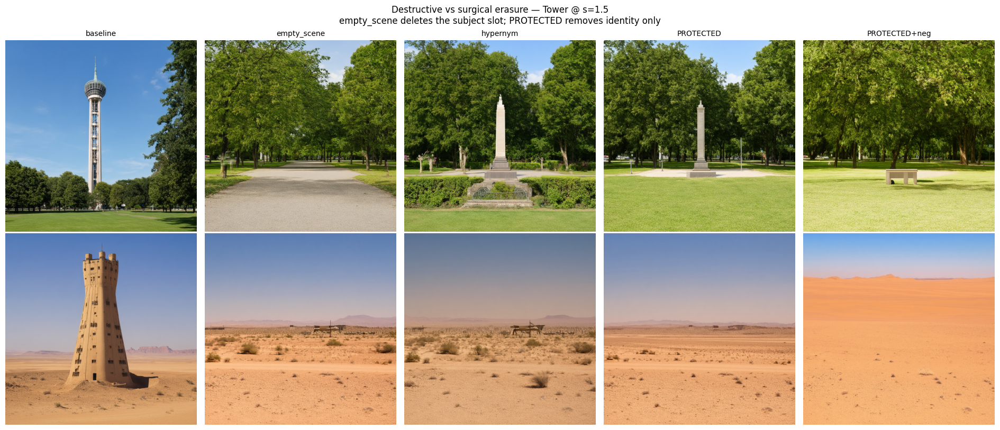

In [10]:
# ----------------------------------------------------------------------------
# CELL 7b — THE ablation: destructive vs surgical (replaces/extends Cell 7)
# Columns: baseline | empty_scene (over-removes) | hypernym | PROTECTED
#          (+ protected+neg on SD3.5)
# ----------------------------------------------------------------------------
SEED = 188
VIS_PROMPTS = make_eval_prompts(TARGET_CONCEPT, TARGET_TYPE)
S_ABL = 1.5
NEG = negative_concept_prompt(TARGET_CONCEPT, TARGET_TYPE) if MODEL_FAMILY == "sd3" else None

sub_empty = er.learn(make_pairs(TARGET_CONCEPT, TARGET_TYPE, n=N_PAIRS,
                                anchor_mode="empty_scene"),
                     k=K_RANK, target_var=TARGET_VAR, k_max_t5=K_MAX_T5,
                     top_tokens=TOP_TOKENS, verbose=False)
sub_prot, sub_id, sub_pres = learn_protected(er, TARGET_CONCEPT, TARGET_TYPE,
                                             n_pairs=N_PAIRS, k=K_RANK,
                                             target_var=TARGET_VAR,
                                             k_max_t5=K_MAX_T5,
                                             top_tokens=TOP_TOKENS, verbose=False)

cols = [("baseline",     None,      dict()),
        ("empty_scene",  sub_empty, dict()),
        ("hypernym",     sub_id,    dict()),
        ("PROTECTED",    sub_prot,  dict())]
if MODEL_FAMILY == "sd3":
    cols.append(("PROTECTED+neg", sub_prot, dict(negative_concept=NEG)))

fig, ax = plt.subplots(len(VIS_PROMPTS), len(cols),
                       figsize=(3.8 * len(cols), 4.2 * len(VIS_PROMPTS)))
if len(VIS_PROMPTS) == 1: ax = np.array([ax])
for r, prompt in enumerate(VIS_PROMPTS):
    for c, (label, s_use, extra) in enumerate(cols):
        img = er.generate(prompt, SEED, sub=s_use,
                          mode=("none" if s_use is None else "all"),
                          strength=S_ABL, token_frac=1.0,
                          neutralize_tokens=False, **extra)
        ax[r, c].imshow(img); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(label, fontsize=10)
        safe = re.sub(r"[^a-zA-Z0-9_]+", "_", label)
        img.save(os.path.join(FIG_DIR,
                 f"surgical_{MODEL_FAMILY}_{TARGET_CONCEPT}_{safe}_p{r}.jpg"))
plt.suptitle(f"Destructive vs surgical erasure — {TARGET_CONCEPT} @ s={S_ABL}\n"
             "empty_scene deletes the subject slot; PROTECTED removes identity only")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR,
            f"surgical_{MODEL_FAMILY}_{TARGET_CONCEPT}.png"), dpi=140)
plt.show()

# Expected outcome per column:
#   empty_scene -> subject gone AND scene drifted (current failure, keep as evidence)
#   hypernym    -> dog becomes another/generic animal, scene intact (replace mode)
#   PROTECTED   -> like hypernym but with presence provably outside the erased
#                  span; if identity/presence overlap was high, may need s=2.0
#   PROTECTED+neg (SD3.5) -> same + CFG suppression for stubborn concepts
#
# If PROTECTED under-removes at s=1.5: raise ONLY the sequence strengths
# (strengths={"pooled":1.5,"clip_seq":2.0,"t5_seq":2.0,"t5":2.0}) before
# touching pooled — pooled overshoot is what causes scene drift.

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

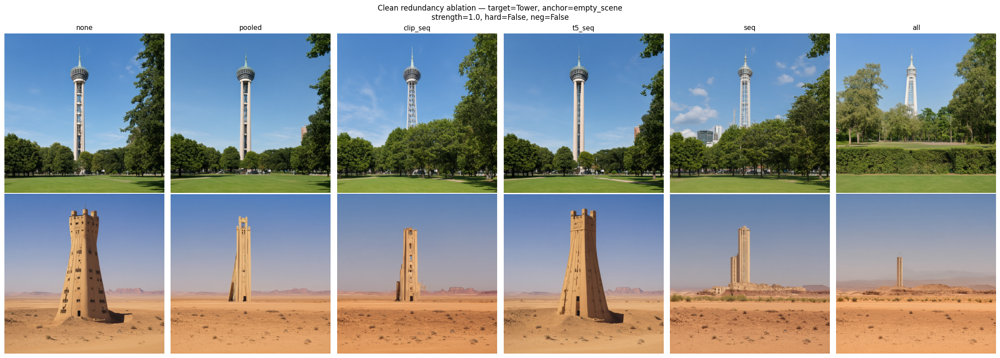

In [11]:
# ============================================================================
# CELL 7: CLEAN REDUNDANCY ABLATION
# ============================================================================

SEED = 188
VIS_PROMPTS = make_eval_prompts(TARGET_CONCEPT, TARGET_TYPE)
modes = ["none", "pooled", "seq", "all"] if MODEL_FAMILY == "flux" else ["none", "pooled", "clip_seq", "t5_seq", "seq", "all"]
REDUNDANCY_STRENGTH = 1.0

fig, ax = plt.subplots(len(VIS_PROMPTS), len(modes), figsize=(3.8 * len(modes), 4.2 * len(VIS_PROMPTS)))
if len(VIS_PROMPTS) == 1: ax = np.array([ax])
for r, prompt in enumerate(VIS_PROMPTS):
    for c, mode in enumerate(modes):
        img = er.generate(prompt, SEED, sub=sub, mode=mode, strength=REDUNDANCY_STRENGTH, token_frac=1.0, neutralize_tokens=False, negative_concept=None)
        ax[r, c].imshow(img); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(mode, fontsize=11)
        img.save(os.path.join(FIG_DIR, f"redund_{MODEL_FAMILY}_{TARGET_CONCEPT}_{ANCHOR_MODE}_{mode}_p{r}.jpg"))
plt.suptitle(f"Clean redundancy ablation — target={TARGET_CONCEPT}, anchor={ANCHOR_MODE}\nstrength={REDUNDANCY_STRENGTH}, hard=False, neg=False")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f"redundancy_{MODEL_FAMILY}_{TARGET_CONCEPT}_{ANCHOR_MODE}.png"), dpi=140); plt.show()

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

... (6 outputs left out)

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

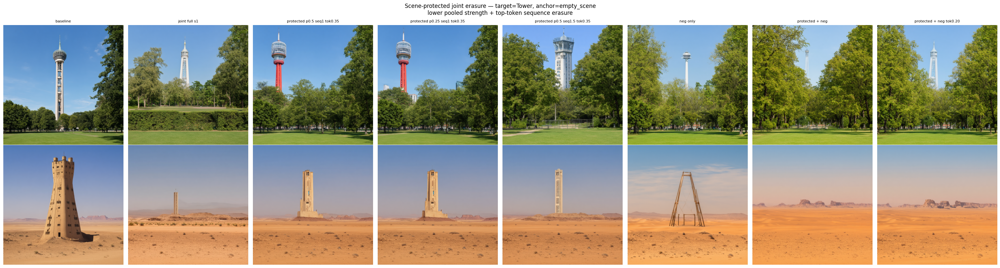

In [12]:
# ============================================================================
# CELL 8: NEW EXPERIMENT — SCENE-PROTECTED JOINT ERASURE
# ============================================================================

SEED = 188
VIS_PROMPTS = make_eval_prompts(TARGET_CONCEPT, TARGET_TYPE)
NEG = negative_concept_prompt(TARGET_CONCEPT, TARGET_TYPE) if MODEL_FAMILY == "sd3" else None
configs = [
    ("baseline", dict(mode="none", strength=0.0, strengths=None, token_frac=1.0, neg=None, hard=False)),
    ("joint full s1", dict(mode="all", strength=1.0, strengths=None, token_frac=1.0, neg=None, hard=False)),
    ("protected p0.5 seq1 tok0.35", dict(mode="all", strength=1.0, strengths={"pooled":0.5,"clip_seq":1.0,"t5_seq":1.0,"t5":1.0}, token_frac=0.35, neg=None, hard=False)),
    ("protected p0.25 seq1 tok0.35", dict(mode="all", strength=1.0, strengths={"pooled":0.25,"clip_seq":1.0,"t5_seq":1.0,"t5":1.0}, token_frac=0.35, neg=None, hard=False)),
    ("protected p0.5 seq1.5 tok0.35", dict(mode="all", strength=1.0, strengths={"pooled":0.5,"clip_seq":1.5,"t5_seq":1.5,"t5":1.5}, token_frac=0.35, neg=None, hard=False)),
]
if MODEL_FAMILY == "sd3":
    configs += [
        ("neg only", dict(mode="none", strength=0.0, strengths=None, token_frac=1.0, neg=NEG, hard=False)),
        ("protected + neg", dict(mode="all", strength=1.0, strengths={"pooled":0.5,"clip_seq":1.0,"t5_seq":1.0}, token_frac=0.35, neg=NEG, hard=False)),
        ("protected + neg tok0.20", dict(mode="all", strength=1.0, strengths={"pooled":0.5,"clip_seq":1.0,"t5_seq":1.0}, token_frac=0.20, neg=NEG, hard=False)),
    ]
fig, ax = plt.subplots(len(VIS_PROMPTS), len(configs), figsize=(3.8 * len(configs), 4.2 * len(VIS_PROMPTS)))
if len(VIS_PROMPTS) == 1: ax = np.array([ax])
for r, prompt in enumerate(VIS_PROMPTS):
    for c, (label, cfg) in enumerate(configs):
        img = er.generate(prompt, SEED, sub=sub, mode=cfg["mode"], strength=cfg["strength"], strengths=cfg["strengths"], token_frac=cfg["token_frac"], neutralize_tokens=cfg["hard"], negative_concept=cfg["neg"], clip_hard_frac=0.10, t5_hard_frac=0.10)
        ax[r, c].imshow(img); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(label, fontsize=8)
        safe = re.sub(r"[^a-zA-Z0-9_]+", "_", label)
        img.save(os.path.join(FIG_DIR, f"protected_{MODEL_FAMILY}_{TARGET_CONCEPT}_{ANCHOR_MODE}_{safe}_p{r}.jpg"))
plt.suptitle(f"Scene-protected joint erasure — target={TARGET_CONCEPT}, anchor={ANCHOR_MODE}\nlower pooled strength + top-token sequence erasure")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f"protected_{MODEL_FAMILY}_{TARGET_CONCEPT}_{ANCHOR_MODE}.png"), dpi=140); plt.show()


Learning anchor=hypernym

Learning anchor=something

Learning anchor=no_animal

Learning anchor=empty_scene


  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

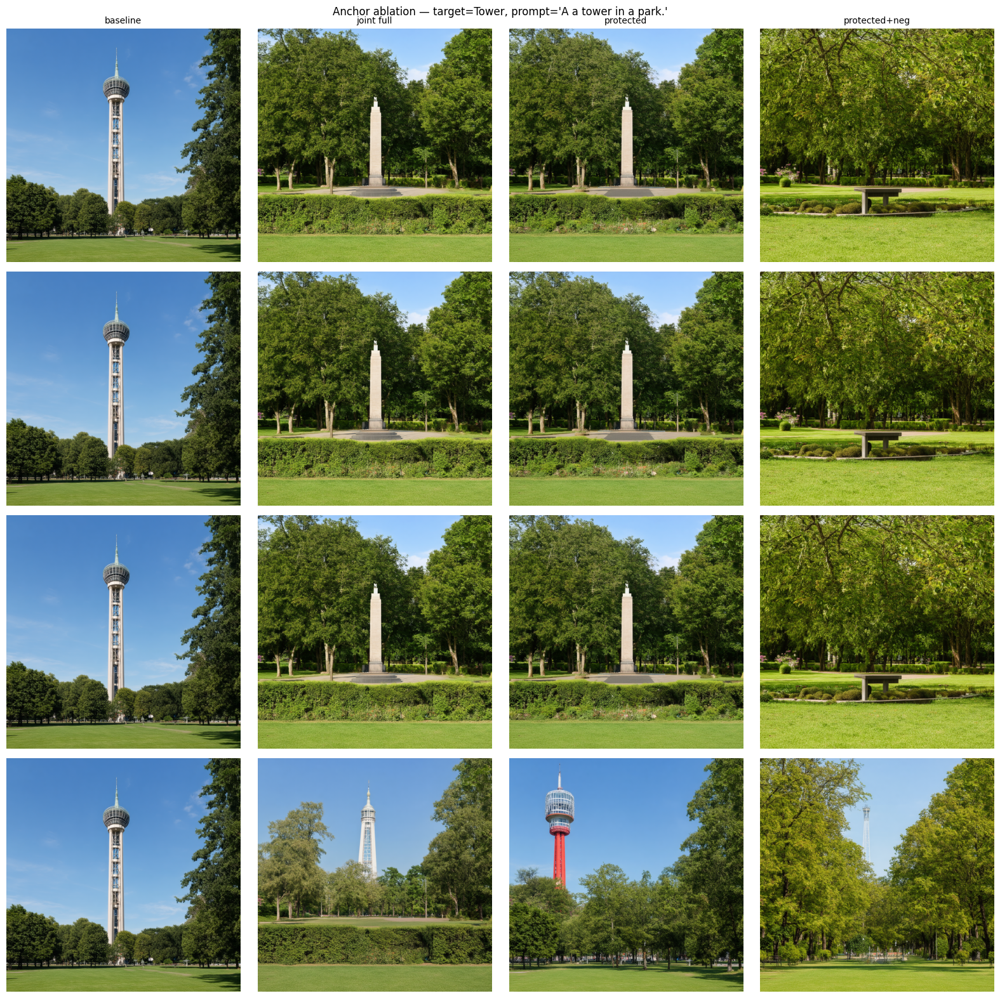

In [13]:
# ============================================================================
# CELL 9: ANCHOR ABLATION
# ============================================================================

if TARGET_TYPE != "object":
    print("Anchor ablation is object-only. Skipping.")
else:
    ANCHORS_TO_TEST = ["hypernym", "something", "no_animal", "empty_scene"]
    SEED = 188
    prompt = make_eval_prompts(TARGET_CONCEPT, TARGET_TYPE)[0]
    neg = negative_concept_prompt(TARGET_CONCEPT, TARGET_TYPE) if MODEL_FAMILY == "sd3" else None
    configs = [
        ("baseline", dict(mode="none", strengths=None, token_frac=1.0, neg=None)),
        ("joint full", dict(mode="all", strengths=None, token_frac=1.0, neg=None)),
        ("protected", dict(mode="all", strengths={"pooled":0.5,"clip_seq":1.0,"t5_seq":1.0,"t5":1.0}, token_frac=0.35, neg=None)),
    ]
    if MODEL_FAMILY == "sd3":
        configs.append(("protected+neg", dict(mode="all", strengths={"pooled":0.5,"clip_seq":1.0,"t5_seq":1.0}, token_frac=0.35, neg=neg)))
    learned = {}
    for a in ANCHORS_TO_TEST:
        print(f"\nLearning anchor={a}")
        pp = make_pairs(TARGET_CONCEPT, TARGET_TYPE, n=N_PAIRS, anchor_mode=a)
        learned[a] = er.learn(pp, k=K_RANK, target_var=TARGET_VAR, k_max_t5=K_MAX_T5, top_tokens=TOP_TOKENS, verbose=False)
    fig, ax = plt.subplots(len(ANCHORS_TO_TEST), len(configs), figsize=(4.0 * len(configs), 4.0 * len(ANCHORS_TO_TEST)))
    for i, a in enumerate(ANCHORS_TO_TEST):
        for j, (label, cfg) in enumerate(configs):
            img = er.generate(prompt, SEED, sub=learned[a], mode=cfg["mode"], strength=1.0, strengths=cfg["strengths"], token_frac=cfg["token_frac"], neutralize_tokens=False, negative_concept=cfg["neg"])
            ax[i, j].imshow(img); ax[i, j].axis("off")
            if i == 0: ax[i, j].set_title(label, fontsize=10)
            if j == 0: ax[i, j].set_ylabel(a, fontsize=11)
            safe = re.sub(r"[^a-zA-Z0-9_]+", "_", f"{a}_{label}")
            img.save(os.path.join(FIG_DIR, f"anchor_ablation_{MODEL_FAMILY}_{TARGET_CONCEPT}_{safe}.jpg"))
    plt.suptitle(f"Anchor ablation — target={TARGET_CONCEPT}, prompt='{prompt}'")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f"anchor_ablation_{MODEL_FAMILY}_{TARGET_CONCEPT}.png"), dpi=140); plt.show()

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

... (30 outputs left out)

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

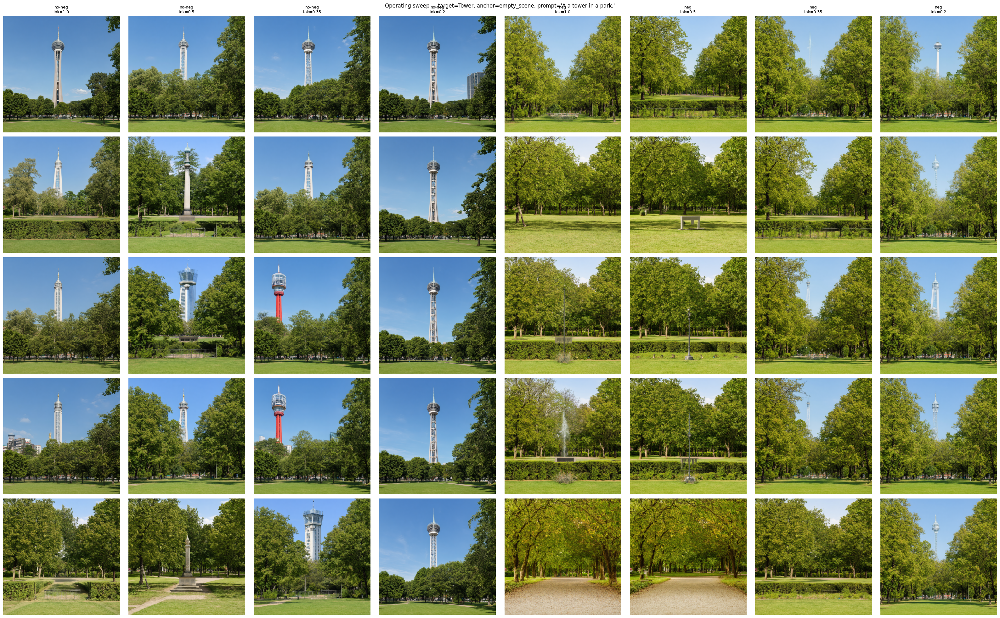

In [14]:
# ============================================================================
# CELL 10: OPERATING-POINT SWEEP
# ============================================================================

SEED = 188
prompt = make_eval_prompts(TARGET_CONCEPT, TARGET_TYPE)[0]
NEG = negative_concept_prompt(TARGET_CONCEPT, TARGET_TYPE) if MODEL_FAMILY == "sd3" else None
STRENGTH_OPTIONS = [
    ("s0.8", {"pooled":0.8,"clip_seq":0.8,"t5_seq":0.8,"t5":0.8}),
    ("s1.0", {"pooled":1.0,"clip_seq":1.0,"t5_seq":1.0,"t5":1.0}),
    ("p0.5_seq1", {"pooled":0.5,"clip_seq":1.0,"t5_seq":1.0,"t5":1.0}),
    ("p0.25_seq1", {"pooled":0.25,"clip_seq":1.0,"t5_seq":1.0,"t5":1.0}),
    ("p0.5_seq1.5", {"pooled":0.5,"clip_seq":1.5,"t5_seq":1.5,"t5":1.5}),
]
TOKEN_FRACS = [1.0, 0.5, 0.35, 0.2]
NEG_OPTIONS = [None, NEG] if MODEL_FAMILY == "sd3" else [None]
fig, ax = plt.subplots(len(STRENGTH_OPTIONS), len(TOKEN_FRACS) * len(NEG_OPTIONS), figsize=(4.0 * len(TOKEN_FRACS) * len(NEG_OPTIONS), 4.0 * len(STRENGTH_OPTIONS)))
if len(STRENGTH_OPTIONS) == 1: ax = np.array([ax])
rows = []
for i, (slabel, strengths) in enumerate(STRENGTH_OPTIONS):
    col = 0
    for neg in NEG_OPTIONS:
        for tf in TOKEN_FRACS:
            img = er.generate(prompt, SEED, sub=sub, mode="all", strength=1.0, strengths=strengths, token_frac=tf, neutralize_tokens=False, negative_concept=neg)
            ax[i, col].imshow(img); ax[i, col].axis("off")
            if i == 0: ax[i, col].set_title(f"{'neg' if neg else 'no-neg'}\ntok={tf}", fontsize=9)
            if col == 0: ax[i, col].set_ylabel(slabel, fontsize=11)
            fn = f"op_{MODEL_FAMILY}_{TARGET_CONCEPT}_{ANCHOR_MODE}_{slabel}_tok{tf}_{'neg' if neg else 'none'}.jpg"
            fp = os.path.join(EVAL_DIR, fn); img.save(fp)
            rows.append({"strength_label":slabel,"strengths":str(strengths),"token_frac":tf,"negative":neg,"path":fp})
            col += 1
plt.suptitle(f"Operating sweep — target={TARGET_CONCEPT}, anchor={ANCHOR_MODE}, prompt='{prompt}'")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f"opsweep_{MODEL_FAMILY}_{TARGET_CONCEPT}_{ANCHOR_MODE}.png"), dpi=140); plt.show()
pd.DataFrame(rows).to_csv(os.path.join(TAB_DIR, f"opsweep_{MODEL_FAMILY}_{TARGET_CONCEPT}_{ANCHOR_MODE}.csv"), index=False)

In [15]:
# ============================================================================
# CELL 11: SMALL MANUAL AUDIT SHEET
# ============================================================================

audit_template = pd.DataFrame([{
    "model": MODEL_FAMILY,
    "concept": TARGET_CONCEPT,
    "type": TARGET_TYPE,
    "anchor": ANCHOR_MODE,
    "setting": "",
    "target_present": "",       # yes / no / partial
    "replacement": "",          # none / same-class / other-object / scene-only
    "scene_retained": "",       # yes / partial / no
    "coherent": "",             # yes / no
    "notes": "",
    "image_path": "",
}])
audit_path = os.path.join(TAB_DIR, f"audit_template_{MODEL_FAMILY}_{TARGET_CONCEPT}_{ANCHOR_MODE}.csv")
audit_template.to_csv(audit_path, index=False)
print("Wrote audit template:", audit_path)
audit_template

Wrote audit template: /content/drive/MyDrive/FULL_v6_sd3.5-medium_clean_ProjectionErasure_/tables/audit_template_sd3_Tower_empty_scene.csv


,model,concept,type,anchor,setting,target_present,replacement,scene_retained,coherent,notes,image_path
0,sd3,Tower,object,empty_scene,,,,,,,


In [16]:
# ============================================================================
# U&ME FULL PAPER EVALUATION — append after v6 Cell 11, run top to bottom.
# Produces EVERY paper artifact:
#   Fig 1  headline qualitative (baseline vs ours, both erase types)
#   Fig 2  redundancy ablation (have from v6 Cell 7 — regenerate w/ final cfg)
#   Fig 3  operating curve (UA / OTR / coherence vs strength)
#   Fig 4  audit (removed vs broken buckets + example strip)
#   Fig 5  diagnostics: residual-energy in-span bars (+ honest controls, from
#          the earlier PathwaySteering notebook — reuse those PNGs)
#   Tab 1  UA / IRA / CRA / OTR ± std per concept, Ours vs in-pipeline
#          baselines (prompt-swap both models; negative-prompt SD3.5)
#   App    anchor ablation, recoverability, hard concept (Impressionism),
#          opsearch table
# Review-response: baselines IN-PIPELINE (same seeds/grid/LLaVA) fixes the
# "copied TRACE numbers" critique; OTR+audit fixes "UA rewards destruction";
# ±std fixes "no error bars". TRACE's published numbers: text mention only.
# ============================================================================

# ============================================================================
# CELL 12: CONFIG
# ============================================================================
EVAL_STYLES  = ["Van_Gogh", "Watercolor", "Cartoon", "Pop_Art", "Winter"]
EVAL_OBJECTS = ["Dogs", "Cats", "Towers", "Birds", "Horses",
                "Flowers", "Trees", "Sandwiches"]
EVAL_SEEDS_B = [188, 288]
FULL_STYLES  = ["Van_Gogh", "Watercolor", "Cartoon", "Cubism", "Winter",
                "Pop_Art", "Ukiyoe", "Impressionism", "Byzantine", "Bricks"]
FULL_OBJECTS = ["Architectures", "Bears", "Birds", "Butterfly", "Cats",
                "Dogs", "Fishes", "Flame", "Flowers", "Frogs",
                "Horses", "Human", "Jellyfish", "Rabbits", "Sandwiches",
                "Sea", "Statues", "Towers", "Trees", "Waterfalls"]
OBJECT_TARGETS   = ["Dogs", "Cats", "Towers", "Birds", "Flowers"]
STYLE_TARGETS    = ["Van_Gogh", "Watercolor", "Cartoon"]
BASELINE_TARGETS = ["Dogs", "Cats", "Towers", "Van_Gogh", "Watercolor"]  # baseline subset

BENCH_DIR = os.path.join(ROOT_DIR, "benchmark")
for s in ["img", "tables", "figs"]:
    os.makedirs(os.path.join(BENCH_DIR, s), exist_ok=True)
B_IMG = os.path.join(BENCH_DIR, "img")
B_TAB = os.path.join(BENCH_DIR, "tables")
B_FIG = os.path.join(BENCH_DIR, "figs")

def bench_prompt(style, obj):
    return f"A {obj.replace('_',' ')} image in {style.replace('_',' ')} style."

def img_path(method, concept, style, obj, seed):
    return os.path.join(B_IMG, f"{MODEL_FAMILY}__{method}__{concept}__{style}__{obj}__{seed}.jpg")

def swap_prompt(style, obj, concept, kind):
    """Prompt-swap baseline: edit the PROMPT (upper-bound comparator, runs in
    the identical pipeline). Objects -> hypernym; styles -> drop style phrase."""
    if kind == "object" and obj == concept:
        return f"A {HYPERNYMS.get(concept,'something')} image in {style.replace('_',' ')} style."
    if kind == "style" and style == concept:
        return f"A {obj.replace('_',' ')} image."
    return bench_prompt(style, obj)

print(f"Grid/concept: {len(EVAL_STYLES)}x{len(EVAL_OBJECTS)}x{len(EVAL_SEEDS_B)}="
      f"{len(EVAL_STYLES)*len(EVAL_OBJECTS)*len(EVAL_SEEDS_B)} | "
      f"targets {len(OBJECT_TARGETS)}obj+{len(STYLE_TARGETS)}sty | "
      f"baselines on {len(BASELINE_TARGETS)} targets")

Grid/concept: 5x8x2=80 | targets 5obj+3sty | baselines on 5 targets


In [17]:
# ============================================================================
# CELL 13: LLAVA (classifier + yes/no + 4-way audit bucket)
# ============================================================================
from transformers import LlavaNextProcessor, LlavaNextForConditionalGeneration

class LLaVA:
    def __init__(self, mid="llava-hf/llava-v1.6-vicuna-7b-hf"):
        self.mid, self.model, self.proc = mid, None, None
    def load(self):
        if self.model is None:
            self.proc = LlavaNextProcessor.from_pretrained(self.mid)
            self.model = LlavaNextForConditionalGeneration.from_pretrained(
                self.mid, torch_dtype=torch.float16, device_map="auto")
    def unload(self):
        if self.model is not None:
            del self.model, self.proc; self.model = self.proc = None
            gc.collect(); torch.cuda.empty_cache()
    def ask(self, image, prompt, max_new=10):
        self.load()
        if isinstance(image, str): image = Image.open(image).convert("RGB")
        conv = [{"role":"user","content":[{"type":"image"},{"type":"text","text":prompt}]}]
        t = self.proc.apply_chat_template(conv, add_generation_prompt=True)
        inp = self.proc(images=image, text=t, return_tensors="pt").to(self.model.device)
        out = self.model.generate(**inp, max_new_tokens=max_new, do_sample=False)
        return self.proc.decode(out[0][inp["input_ids"].shape[1]:],
                                skip_special_tokens=True).strip()
    def classify(self, image, options, domain):
        opts = "\n".join(f"{i+1}. {o.replace('_',' ')}" for i, o in enumerate(options))
        head = ("You are an image classifier. Classify the artistic style of the given image."
                if domain == "style" else "Classify the object depicted in this image.")
        r = self.ask(image, f"{head}\nChoose exactly one option from the numbered list "
                            f"below. Respond with only the number.\nOptions:\n{opts}")
        m = re.findall(r"\d+", r)
        if m and 1 <= int(m[0]) <= len(options): return options[int(m[0]) - 1]
        rl = r.lower()
        for o in options:
            if o.lower().replace("_", " ") in rl: return o
        return None
    def yes(self, image, q):
        return "yes" in self.ask(image, q + " Answer with only yes or no.").lower()
    def bucket(self, image, concept, kind):
        c = concept.replace("_", " ")
        if kind == "object":
            if self.yes(image, f"Is there a {c} in this image?"): return "target_remains"
            if not self.yes(image, "Is this a normal, coherent image (not noise, "
                                   "not blank, not broken)?"):    return "destroyed"
            if self.yes(image, "Is there another clearly visible main object or "
                               "animal in this image?"):           return "replaced"
            return "clean_removal"
        if self.yes(image, f"Is this image in {c} style?"):        return "target_remains"
        if not self.yes(image, "Is this a normal, coherent image (not noise, "
                               "not blank, not broken)?"):         return "destroyed"
        return "clean_removal"

llava = LLaVA()
print("✓ LLaVA ready (lazy)")

✓ LLaVA ready (lazy)


In [ ]:

# ============================================================================
# CELL 14 (CORRECTED): OPERATING-POINT SEARCH
# Fixes KeyError: False — guards empty groups / None predictions / empty filters.
# ============================================================================
def object_configs():
    cfgs = [("empty_s1.5",  dict(anchor="empty_scene", strength=1.5, strengths=None,
                                 token_frac=1.0, neg=False)),
            ("empty_prot",  dict(anchor="empty_scene", strength=1.0,
                                 strengths={"pooled":0.5,"clip_seq":1.5,"t5_seq":1.5,"t5":1.5},
                                 token_frac=0.35, neg=False)),
            ("hyper_s1.5",  dict(anchor="hypernym", strength=1.5, strengths=None,
                                 token_frac=1.0, neg=False))]
    if MODEL_FAMILY == "sd3":
        cfgs.append(("empty_prot_neg", dict(anchor="empty_scene", strength=1.0,
                     strengths={"pooled":0.5,"clip_seq":1.5,"t5_seq":1.5},
                     token_frac=0.35, neg=True)))
    return cfgs

def style_configs():
    return [(f"style_s{s}", dict(anchor="hypernym", strength=s, strengths=None,
                                 token_frac=1.0, neg=False)) for s in (1.0, 1.5, 2.0)]

def get_sub(concept, kind, anchor_mode):
    sp = os.path.join(SUB_DIR, f"bench_{concept}_{MODEL_FAMILY}_{anchor_mode}.pt")
    if os.path.exists(sp):
        return er.load(sp)
    prs = (make_pairs(concept, kind, n=N_PAIRS, anchor_mode=anchor_mode)
           if kind == "object" else make_pairs(concept, kind, n=N_PAIRS))
    s = er.learn(prs, k=K_RANK, target_var=TARGET_VAR, k_max_t5=K_MAX_T5,
                 top_tokens=TOP_TOKENS, verbose=False)
    er.save(s, sp)
    return s

def ours_generate(prompt, seed, sub, cfg, concept, kind):
    neg = (negative_concept_prompt(concept, kind)
           if (cfg.get("neg") and MODEL_FAMILY == "sd3") else None)
    return er.generate(prompt, seed, sub=sub, mode="all",
                       strength=cfg.get("strength", 1.0), strengths=cfg.get("strengths"),
                       token_frac=cfg.get("token_frac", 1.0),
                       neutralize_tokens=False, negative_concept=neg)

PROXY = [(st, ob, sd) for st in ("Van_Gogh", "Cartoon")
         for ob in ("Dogs", "Cats", "Towers") for sd in (188,)]

def _pct(series_bool):
    """Safe percentage: returns np.nan for an empty selection instead of
    letting an empty/scalar reduction collapse into a bad index."""
    s = pd.Series(series_bool)
    return float(100.0 * s.mean()) if len(s) else float("nan")

def run_opsearch(kind):
    concept = {"object": "Dogs", "style": "Van_Gogh"}[kind]
    cfgs = object_configs() if kind == "object" else style_configs()

    # ---- Phase A: generate proxy images ------------------------------------
    recs = []
    for name, cfg in cfgs:
        anchor = cfg["anchor"] if kind == "object" else "hypernym"
        sub_u = get_sub(concept, kind, anchor)
        for st, ob, sd in PROXY:
            fp = img_path(f"ops_{name}", concept, st, ob, sd)
            if not os.path.exists(fp):
                ours_generate(bench_prompt(st, ob), sd, sub_u, cfg, concept, kind).save(fp)
            recs.append(dict(config=name, style=st, obj=ob, seed=sd, path=fp))

    # ---- Phase B: classify --------------------------------------------------
    pipe.to("cpu"); gc.collect(); torch.cuda.empty_cache()
    rows = []
    for r in tqdm(recs, desc=f"opsearch {kind}"):
        rows.append({
            **r,
            "pred_style": llava.classify(r["path"], FULL_STYLES, "style"),
            "pred_obj":   llava.classify(r["path"], FULL_OBJECTS, "object"),
            "coherent":   bool(llava.yes(r["path"], "Is this a normal, coherent image "
                                         "(not noise, not blank, not broken)?")),
        })
    llava.unload(); pipe.to(DEVICE)

    df = pd.DataFrame(rows)
    # normalize dtypes so comparisons never produce surprises
    for col in ("pred_style", "pred_obj", "style", "obj", "config"):
        df[col] = df[col].astype("object")

    out = []
    for name in [c[0] for c in cfgs]:                 # iterate config NAMES explicitly
        g = df[df["config"] == name]
        if not len(g):
            print(f"⚠ no rows for config {name}; skipping")
            continue
        if kind == "object":
            tgt = g[g["obj"] == concept]
            ret = g[g["obj"] != concept]
            UA  = _pct(tgt["pred_obj"] != concept)
            OTR = _pct(tgt["pred_style"] == tgt["style"])
            IRA = _pct(ret["pred_obj"] == ret["obj"])
            CRA = _pct(ret["pred_style"] == ret["style"])
        else:
            tgt = g[g["style"] == concept]
            ret = g[g["style"] != concept]
            UA  = _pct(tgt["pred_style"] != concept)
            OTR = _pct(tgt["pred_obj"] == tgt["obj"])
            IRA = _pct(ret["pred_style"] == ret["style"])
            CRA = _pct(ret["pred_obj"] == ret["obj"])
        COH = _pct(g["coherent"])
        parts = [v for v in (UA, IRA, CRA, OTR) if not np.isnan(v)]
        comp = round(0.4*np.nan_to_num(UA) + 0.2*np.nan_to_num(IRA)
                     + 0.2*np.nan_to_num(CRA) + 0.2*np.nan_to_num(OTR), 1) if parts else float("nan")
        out.append(dict(config=name, UA=round(UA,1), IRA=round(IRA,1),
                        CRA=round(CRA,1), OTR=round(OTR,1),
                        coherent=round(COH,1), composite=comp))

    if not out:
        raise RuntimeError(f"opsearch produced no scored configs for {kind} — "
                           "check that PROXY images generated and LLaVA returned labels.")

    T = pd.DataFrame(out).sort_values("composite", ascending=False, na_position="last")
    print(T.to_string(index=False))
    T.to_csv(os.path.join(B_TAB, f"opsearch_{MODEL_FAMILY}_{kind}.csv"), index=False)

    ok = T[T["coherent"] >= 80]
    best_row = ok.iloc[0] if len(ok) else T.iloc[0]
    best = best_row["config"]
    print(f"SELECTED {kind}: {best}  <- eyeball its proxy images before Phase A!")
    return best, dict(cfgs)[best]

BEST_OBJ_NAME, BEST_OBJ_CFG = run_opsearch("object")
BEST_STY_NAME, BEST_STY_CFG = run_opsearch("style")

saved /content/drive/MyDrive/FULL_v6_sd3.5-medium_clean_ProjectionErasure_/subspaces/bench_Dogs_sd3_empty_scene.pt


  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

In [ ]:
# ============================================================================
# CELL 15: PHASE A — generate everything (resume-safe): shared baseline grid,
# OURS per target, PROMPT-SWAP per baseline target, NEG-PROMPT (SD3.5 only)
# ============================================================================
TARGETS = [(c, "object", BEST_OBJ_CFG) for c in OBJECT_TARGETS] + \
          [(c, "style",  BEST_STY_CFG) for c in STYLE_TARGETS]
GRID = [(st, ob, sd) for st in EVAL_STYLES for ob in EVAL_OBJECTS for sd in EVAL_SEEDS_B]

pipe.to(DEVICE)
for st, ob, sd in tqdm(GRID, desc="shared baseline"):
    fp = img_path("none", "none", st, ob, sd)
    if not os.path.exists(fp):
        er.generate(bench_prompt(st, ob), sd, sub=None, mode="none").save(fp)

for concept, kind, cfg in TARGETS:
    sub_c = get_sub(concept, kind, cfg["anchor"] if kind == "object" else "hypernym")
    for st, ob, sd in tqdm(GRID, desc=f"ours {concept}"):
        fp = img_path("ours", concept, st, ob, sd)
        if not os.path.exists(fp):
            ours_generate(bench_prompt(st, ob), sd, sub_c, cfg, concept, kind).save(fp)
    gc.collect(); torch.cuda.empty_cache()

for concept, kind, _ in TARGETS:
    if concept not in BASELINE_TARGETS: continue
    for st, ob, sd in tqdm(GRID, desc=f"promptswap {concept}"):
        fp = img_path("pswap", concept, st, ob, sd)
        if not os.path.exists(fp):
            er.generate(swap_prompt(st, ob, concept, kind), sd,
                        sub=None, mode="none").save(fp)
    if MODEL_FAMILY == "sd3":
        for st, ob, sd in tqdm(GRID, desc=f"negprompt {concept}"):
            fp = img_path("negp", concept, st, ob, sd)
            if not os.path.exists(fp):
                er.generate(bench_prompt(st, ob), sd, sub=None, mode="none",
                            negative_concept=negative_concept_prompt(concept, kind)).save(fp)

In [24]:
# ============================================================================
# CELL 16: PHASE B — one LLaVA pass over everything (CSV cache, resume-safe)
# ============================================================================
pipe.to("cpu"); gc.collect(); torch.cuda.empty_cache()
cls_csv = os.path.join(B_TAB, f"classifications_{MODEL_FAMILY}.csv")
rows, done = [], set()
if os.path.exists(cls_csv):
    prev = pd.read_csv(cls_csv); rows = prev.to_dict("records"); done = set(prev.path)

def enum_jobs():
    for concept, kind, _ in TARGETS:
        methods = ["ours"] + (["pswap"] if concept in BASELINE_TARGETS else []) + \
                  (["negp"] if (MODEL_FAMILY == "sd3" and concept in BASELINE_TARGETS) else [])
        for m in methods:
            for st, ob, sd in GRID:
                fp = img_path(m, concept, st, ob, sd)
                if os.path.exists(fp):
                    yield dict(method=m, concept=concept, kind=kind,
                               style=st, obj=ob, seed=sd, path=fp)

todo = [j for j in enum_jobs() if j["path"] not in done]
for i, r in enumerate(tqdm(todo, desc="Phase B")):
    r["pred_style"] = llava.classify(r["path"], FULL_STYLES, "style")
    r["pred_obj"]   = llava.classify(r["path"], FULL_OBJECTS, "object")
    is_target = (r["obj"] == r["concept"]) if r["kind"] == "object" else (r["style"] == r["concept"])
    r["bucket"] = llava.bucket(r["path"], r["concept"], r["kind"]) \
                  if (is_target and r["method"] == "ours") else ""
    rows.append(r)
    if (i + 1) % 50 == 0: pd.DataFrame(rows).to_csv(cls_csv, index=False)
pd.DataFrame(rows).to_csv(cls_csv, index=False)
llava.unload(); pipe.to(DEVICE)
print("Phase B done ->", cls_csv)


Phase B:   0%|          | 0/1040 [00:00<?, ?it/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/687 [00:00<?, ?it/s]

Phase B done -> /content/drive/MyDrive/FULL_v6_schnell_clean_ProjectionErasure_/benchmark/tables/classifications_flux.csv


In [26]:
# ============================================================================
# CELL 17 (CORRECTED): TABLE 1 — UA/IRA/CRA/OTR ± std over seeds
# Fixes:
#  (1) CRA/OTR = 0.0 bug: LLaVA returns display labels ("Van Gogh") but the
#      grid stores canonical labels ("Van_Gogh"). Normalize BOTH sides before
#      every comparison so exact-match metrics work.
#  (2) KeyError: False: guard empty groups / empty 'ours' before building AVERAGE.
# ============================================================================
df = pd.read_csv(cls_csv)
if "bucket" in df.columns:
    df["bucket"] = df["bucket"].fillna("")

def _norm(x):
    """Canonicalize a label: lowercase, strip, unify separators.
    Makes 'Van Gogh' == 'Van_Gogh' == 'van gogh'. Handles NaN/None -> ''."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ""
    return str(x).strip().lower().replace("_", " ")

for col in ("pred_style", "pred_obj", "style", "obj", "concept", "kind", "method"):
    if col in df.columns:
        df[col + "_n"] = df[col].map(_norm)

def _pct(mask):
    s = pd.Series(mask)
    return float(100.0 * s.mean()) if len(s) else float("nan")

def metr(g, concept, kind):
    cn = _norm(concept)
    if not len(g):
        return dict(UA=float("nan"), IRA=float("nan"), CRA=float("nan"), OTR=float("nan"))
    if kind == "object":
        t  = g[g.obj_n == cn]
        rt = g[g.obj_n != cn]
        return dict(UA =_pct(t.pred_obj_n   != cn),
                    IRA=_pct(rt.pred_obj_n  == rt.obj_n),
                    CRA=_pct(rt.pred_style_n== rt.style_n),
                    OTR=_pct(t.pred_style_n == t.style_n))
    t  = g[g.style_n == cn]
    rt = g[g.style_n != cn]
    return dict(UA =_pct(t.pred_style_n  != cn),
                IRA=_pct(rt.pred_style_n == rt.style_n),
                CRA=_pct(rt.pred_obj_n   == rt.obj_n),
                OTR=_pct(t.pred_obj_n    == t.obj_n))

for kind in ("object", "style"):
    body = []
    for concept, k2, _ in TARGETS:
        if k2 != kind:
            continue
        for method, label in (("ours", "Ours"), ("pswap", "Prompt-swap"), ("negp", "Neg-prompt")):
            g = df[(df.concept_n == _norm(concept)) &
                   (df.kind_n == _norm(kind)) &
                   (df.method_n == _norm(method))]
            if not len(g):
                continue
            per_seed = [metr(g[g.seed == sd], concept, kind) for sd in EVAL_SEEDS_B]
            agg = metr(g, concept, kind)
            row = {"Concept": concept, "Method": label}
            for m in ("UA", "IRA", "CRA", "OTR"):
                vals = [p[m] for p in per_seed if not np.isnan(p[m])]
                std = np.std(vals) if vals else 0.0
                row[m] = f"{agg[m]:.1f} ± {std:.1f}" if not np.isnan(agg[m]) else "n/a"
                row["_" + m] = agg[m]
            body.append(row)

    T = pd.DataFrame(body)
    if not len(T):
        print(f"⚠ no classified rows yet for kind={kind}; skipping table")
        continue

    ours = T[T.Method == "Ours"]
    display_cols = [c for c in T.columns if not c.startswith("_")]
    if len(ours):
        avg = {"Concept": "AVERAGE", "Method": "Ours"}
        for m in ("UA", "IRA", "CRA", "OTR"):
            col = "_" + m
            vals = ours[col].dropna() if col in ours.columns else pd.Series([], dtype=float)
            avg[m] = f"{vals.mean():.1f}" if len(vals) else "n/a"
        Tshow = pd.concat([T[display_cols], pd.DataFrame([avg])], ignore_index=True)
    else:
        Tshow = T[display_cols]

    print(f"\n== TABLE 1{'a' if kind == 'object' else 'b'}: {MODEL_FAMILY} {kind} "
          f"(ours cfg: {BEST_OBJ_NAME if kind == 'object' else BEST_STY_NAME}) ==")
    print(Tshow.to_string(index=False))
    Tshow.to_csv(os.path.join(B_TAB, f"table1_{MODEL_FAMILY}_{kind}.csv"), index=False)

# Sanity check you SHOULD run once after this cell:
#   df[df.method=='ours'][['style','pred_style']].drop_duplicates().head(20)
# Confirm pred_style values actually look like the style names. If pred_style
# is often blank/None, the classifier isn't parsing LLaVA output -> fix that
# BEFORE trusting CRA/OTR (normalization can't rescue empty predictions).
# Paper note: TRACE's published numbers -> TEXT only, marked non-comparable.


== TABLE 1a: flux object (ours cfg: empty_s1.5) ==
Concept      Method          UA         IRA        CRA         OTR
   Dogs        Ours 100.0 ± 0.0 100.0 ± 0.0 35.7 ± 4.3 100.0 ± 0.0
   Dogs Prompt-swap 70.0 ± 10.0 100.0 ± 0.0 48.6 ± 0.0  60.0 ± 0.0
   Cats        Ours 100.0 ± 0.0 100.0 ± 0.0 44.3 ± 4.3 90.0 ± 10.0
   Cats Prompt-swap 60.0 ± 20.0 100.0 ± 0.0 48.6 ± 0.0  60.0 ± 0.0
 Towers        Ours 100.0 ± 0.0 100.0 ± 0.0 48.6 ± 5.7  80.0 ± 0.0
 Towers Prompt-swap 60.0 ± 40.0 100.0 ± 0.0 50.0 ± 1.4  40.0 ± 0.0
  Birds        Ours 100.0 ± 0.0 100.0 ± 0.0 38.6 ± 4.3 100.0 ± 0.0
Flowers        Ours 90.0 ± 10.0 100.0 ± 0.0 42.9 ± 2.9 100.0 ± 0.0
AVERAGE        Ours        98.0       100.0       42.0        94.0

== TABLE 1b: flux style (ours cfg: style_s1.0) ==
   Concept      Method          UA        IRA         CRA         OTR
  Van_Gogh        Ours 100.0 ± 0.0 60.9 ± 1.6 100.0 ± 0.0 100.0 ± 0.0
  Van_Gogh Prompt-swap  62.5 ± 0.0 59.4 ± 3.1 100.0 ± 0.0 100.0 ± 0.0
Watercolor       

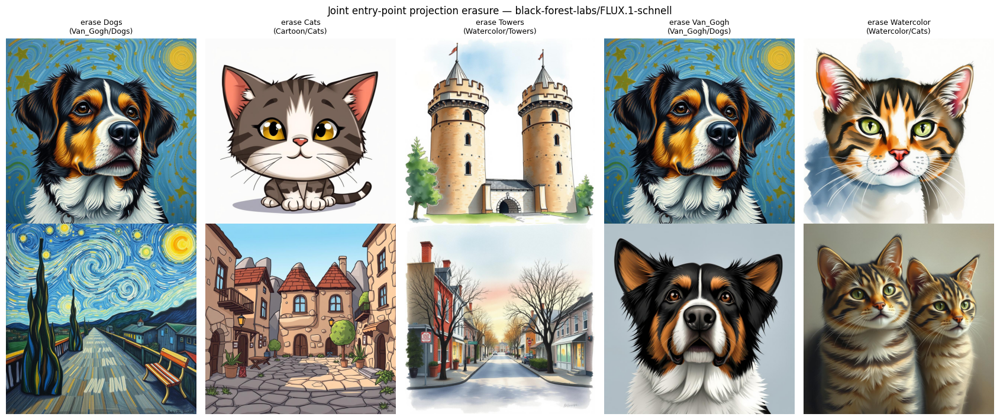

In [27]:
# ============================================================================
# CELL 18: FIG 1 — headline qualitative (baseline vs ours)
# ============================================================================
SHOW = [("Dogs","object","Van_Gogh","Dogs"), ("Cats","object","Cartoon","Cats"),
        ("Towers","object","Watercolor","Towers"),
        ("Van_Gogh","style","Van_Gogh","Dogs"), ("Watercolor","style","Watercolor","Cats")]
SD0 = EVAL_SEEDS_B[0]
fig, ax = plt.subplots(2, len(SHOW), figsize=(3.4*len(SHOW), 7.2))
for c, (concept, kind, st, ob) in enumerate(SHOW):
    for r, m in enumerate((("none","none"), ("ours",concept))):
        p = img_path(m[0], m[1], st, ob, SD0)
        if os.path.exists(p): ax[r, c].imshow(Image.open(p))
        ax[r, c].axis("off")
    ax[0, c].set_title(f"erase {concept}\n({st}/{ob})", fontsize=9)
plt.suptitle(f"Joint entry-point projection erasure — {MODEL_ID}")
plt.tight_layout(); plt.savefig(os.path.join(B_FIG, f"fig1_{MODEL_FAMILY}.png"), dpi=150)
plt.show()

curve LLaVA:   0%|          | 0/60 [00:00<?, ?it/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/687 [00:00<?, ?it/s]

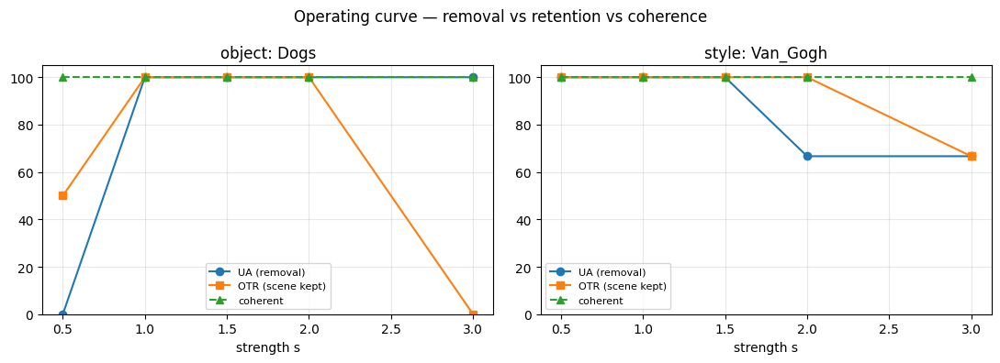

In [29]:
# ============================================================================
# CELL 19 (CORRECTED): FIG 3 — operating curve (UA/OTR/coherence vs strength)
# Fixes: label normalization (Van Gogh vs Van_Gogh -> OTR no longer flat 0)
#        and empty-selection guards (KeyError: False).
# ============================================================================
CURVE_S = [0.5, 1.0, 1.5, 2.0, 3.0]

def _norm(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ""
    return str(x).strip().lower().replace("_", " ")

def _pct(mask):
    s = pd.Series(mask)
    return float(100.0 * s.mean()) if len(s) else float("nan")

# ---- Phase A: generate curve images ----------------------------------------
curve_rows = []
for kind, concept in (("object", "Dogs"), ("style", "Van_Gogh")):
    base_cfg = dict(BEST_OBJ_CFG if kind == "object" else BEST_STY_CFG)
    sub_u = get_sub(concept, kind, base_cfg["anchor"] if kind == "object" else "hypernym")
    for s in CURVE_S:
        cfg = dict(base_cfg); cfg["strength"] = s
        if cfg.get("strengths"):
            base_s = base_cfg.get("strength", 1.0) or 1.0
            cfg["strengths"] = {k2: v * s / base_s for k2, v in base_cfg["strengths"].items()}
        for st, ob, sd in PROXY:
            fp = img_path(f"curve_s{s}", concept, st, ob, sd)
            if not os.path.exists(fp):
                ours_generate(bench_prompt(st, ob), sd, sub_u, cfg, concept, kind).save(fp)
            curve_rows.append(dict(kind=kind, concept=concept, s=s,
                                   style=st, obj=ob, path=fp))

# ---- Phase B: classify ------------------------------------------------------
pipe.to("cpu"); gc.collect(); torch.cuda.empty_cache()
crows = []
for r in tqdm(curve_rows, desc="curve LLaVA"):
    crows.append({**r,
        "pred_style": llava.classify(r["path"], FULL_STYLES, "style"),
        "pred_obj":   llava.classify(r["path"], FULL_OBJECTS, "object"),
        "coherent":   bool(llava.yes(r["path"], "Is this a normal, coherent image "
                                     "(not noise, not blank, not broken)?"))})
llava.unload(); pipe.to(DEVICE)

cdf = pd.DataFrame(crows)
# normalized columns for safe comparison
for col in ("pred_style", "pred_obj", "style", "obj", "kind", "concept"):
    cdf[col + "_n"] = cdf[col].map(_norm)

# ---- Plot -------------------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for i, (kind, concept) in enumerate((("object", "Dogs"), ("style", "Van_Gogh"))):
    cn = _norm(concept)
    g = cdf[cdf.kind_n == _norm(kind)]
    xs, ua, otr, coh = [], [], [], []
    for s in CURVE_S:
        gs = g[g.s == s]
        if kind == "object":
            t = gs[gs.obj_n == cn]
            ua.append(_pct(t.pred_obj_n != cn))
            otr.append(_pct(t.pred_style_n == t.style_n))
        else:
            t = gs[gs.style_n == cn]
            ua.append(_pct(t.pred_style_n != cn))
            otr.append(_pct(t.pred_obj_n == t.obj_n))
        coh.append(_pct(gs.coherent))
        xs.append(s)
    axs[i].plot(xs, ua,  "o-",  label="UA (removal)")
    axs[i].plot(xs, otr, "s-",  label="OTR (scene kept)")
    axs[i].plot(xs, coh, "^--", label="coherent")
    axs[i].set_title(f"{kind}: {concept}")
    axs[i].set_xlabel("strength s"); axs[i].set_ylim(0, 105)
    axs[i].legend(fontsize=8); axs[i].grid(alpha=.3)
plt.suptitle("Operating curve — removal vs retention vs coherence")
plt.tight_layout()
plt.savefig(os.path.join(B_FIG, f"fig3_curve_{MODEL_FAMILY}.png"), dpi=150)
plt.show()
cdf.to_csv(os.path.join(B_TAB, f"curve_{MODEL_FAMILY}.csv"), index=False)

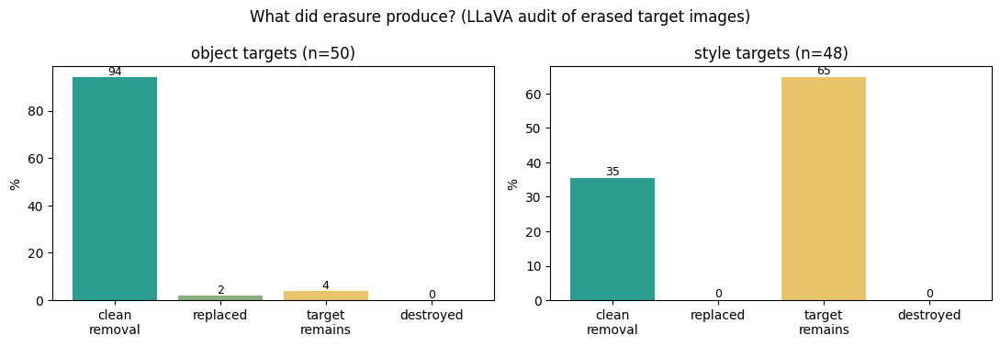

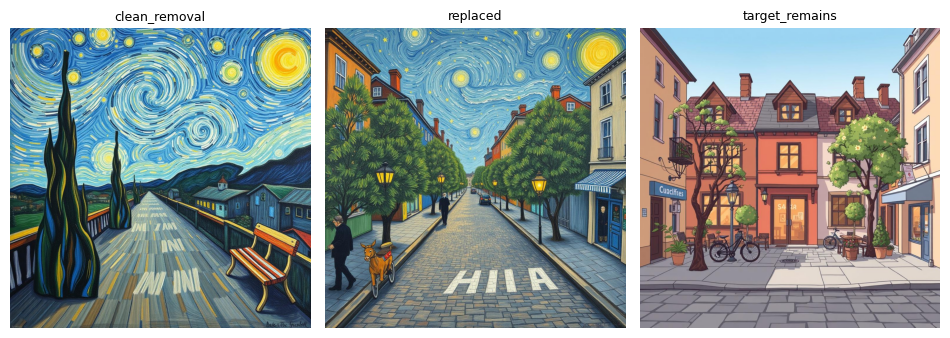

In [30]:
# ============================================================================
# CELL 20: FIG 4 — audit (buckets from Phase B) + example strip
# ============================================================================
aud = df[(df.method == "ours") & (df.bucket != "")]
order = ["clean_removal", "replaced", "target_remains", "destroyed"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for i, kind in enumerate(("object", "style")):
    g = aud[aud.kind == kind]
    frac = [100 * (g.bucket == b).mean() if len(g) else 0 for b in order]
    axs[i].bar([b.replace("_", "\n") for b in order], frac,
               color=["#2a9d8f", "#8ab17d", "#e9c46a", "#e76f51"])
    axs[i].set_title(f"{kind} targets (n={len(g)})"); axs[i].set_ylabel("%")
    for x, v in enumerate(frac): axs[i].text(x, v + 1, f"{v:.0f}", ha="center", fontsize=9)
plt.suptitle("What did erasure produce? (LLaVA audit of erased target images)")
plt.tight_layout(); plt.savefig(os.path.join(B_FIG, f"fig4_audit_{MODEL_FAMILY}.png"), dpi=150)
plt.show()
strip = aud.groupby("bucket").head(1)
if len(strip):
    fig, axs2 = plt.subplots(1, len(strip), figsize=(3.2*len(strip), 3.4))
    axs2 = np.atleast_1d(axs2)
    for a, (_, r) in zip(axs2, strip.iterrows()):
        a.imshow(Image.open(r.path)); a.axis("off"); a.set_title(r.bucket, fontsize=9)
    plt.tight_layout(); plt.savefig(os.path.join(B_FIG, f"fig4b_examples_{MODEL_FAMILY}.png"), dpi=150)
    plt.show()

Residual energy probe='token'
  pos: a photo of a dog in a park.
  neg: a photo of an empty park.
pooled    | in_span= 0.72 | before=   10.22 after=    1.59 | removed=  84.4% | rank=4
t5        | in_span= 0.81 | before=    0.92 after=    0.33 | removed=  64.4% | rank=24
Residual energy probe='token'
  pos: a painting of a mountain in Van Gogh style.
  neg: a painting of a mountain.
pooled    | in_span= 0.59 | before=   10.65 after=    0.92 | removed=  91.4% | rank=4
t5        | in_span= 0.92 | before=    0.12 after=    0.15 | removed= -25.6% | rank=24

Residual-energy diagnostic table:
 concept   kind carrier  in_span    before    after    removed  rank
    Dogs object  pooled 0.718033 10.215599 1.594069  84.395733     4
    Dogs object      t5 0.808206  0.917443 0.326419  64.420778    24
Van_Gogh  style  pooled 0.594063 10.645880 0.919026  91.367310     4
Van_Gogh  style      t5 0.915852  0.117381 0.147397 -25.571435    24

Saved diagnostic table to: /content/drive/MyDrive/FULL_v6_sch

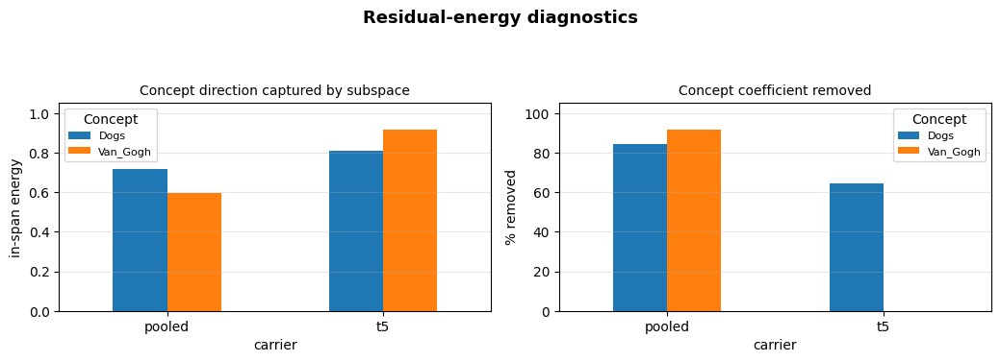

Saved diagnostic figure to: /content/drive/MyDrive/FULL_v6_schnell_clean_ProjectionErasure_/benchmark/figs/fig5_diag_flux.png


In [38]:
# ============================================================================
# CELL 21: FIG 5 — diagnostics: in-span bars (residual-energy) per carrier
# ============================================================================

diag_rows = []

def safe_float(x, default=None):
    """Convert x to float safely."""
    if x is None:
        return default
    try:
        return float(x)
    except Exception:
        return default


def parse_residual_row(row):
    """
    Robust parser for residual_energy rows.

    Supports:
      - tuple/list rows:
          (carrier, in_span, before, after, removed)
          (carrier, in_span, before, after, removed, rank)
          rows with extra values
      - dict rows with possible alternative removed-key names
    """

    # -------------------------
    # Case 1: dictionary row
    # -------------------------
    if isinstance(row, dict):
        carrier = row.get("carrier", row.get("name", row.get("pathway")))
        in_span = row.get("in_span", row.get("inspan"))
        before = row.get("before")
        after = row.get("after")
        rank = row.get("rank", None)

        # Try multiple possible names for removed
        removed = (
            row.get("removed")
            if row.get("removed") is not None
            else row.get("removed_frac")
            if row.get("removed_frac") is not None
            else row.get("frac_removed")
            if row.get("frac_removed") is not None
            else row.get("removed_fraction")
        )

    # -------------------------
    # Case 2: tuple/list row
    # -------------------------
    elif isinstance(row, (tuple, list)):
        vals = list(row)

        # Sometimes rows from itertuples include index first:
        # (0, "pooled", 0.72, ...)
        if len(vals) >= 6 and not isinstance(vals[0], str) and isinstance(vals[1], str):
            vals = vals[1:]

        if len(vals) < 4:
            raise ValueError(f"Residual row has too few values: {row}")

        carrier = vals[0]
        in_span = vals[1]
        before = vals[2]
        after = vals[3]

        # If available, assume 5th value is removed and 6th is rank.
        removed = vals[4] if len(vals) >= 5 else None
        rank = vals[5] if len(vals) >= 6 else None

    else:
        raise TypeError(f"Unsupported residual row type: {type(row)} | row={row}")

    # Convert numeric fields
    in_span = safe_float(in_span)
    before = safe_float(before)
    after = safe_float(after)
    removed = safe_float(removed)

    # If removed is missing, compute it from before/after.
    # This fixes the NoneType error.
    if removed is None:
        if before is not None and after is not None and abs(before) > 1e-8:
            removed = (before - after) / before
        else:
            removed = 0.0

    # If residual_energy returned removed as a percentage, convert to fraction.
    # Example: 84.4 -> 0.844
    if removed > 1.5:
        removed = removed / 100.0

    return {
        "carrier": carrier,
        "in_span": in_span,
        "before": before,
        "after": after,
        "removed": removed,
        "rank": rank,
    }


for concept, kind in (("Dogs", "object"), ("Van_Gogh", "style")):
    am = BEST_OBJ_CFG["anchor"] if kind == "object" else "hypernym"
    sub_u = get_sub(concept, kind, am)

    res = residual_energy(
        er,
        sub_u,
        concept,
        kind,
        anchor_mode=am if kind == "object" else "hypernym",
        probe="token",
    )

    # Handle case where residual_energy returns a DataFrame
    if isinstance(res, pd.DataFrame):
        iterable_rows = res.to_dict("records")
    else:
        iterable_rows = res

    for row in iterable_rows:
        parsed = parse_residual_row(row)

        diag_rows.append(
            dict(
                concept=concept,
                kind=kind,
                carrier=parsed["carrier"],
                in_span=float(parsed["in_span"]),
                before=float(parsed["before"]),
                after=float(parsed["after"]),
                removed=100.0 * float(parsed["removed"]),
                rank=parsed["rank"],
            )
        )


ddf = pd.DataFrame(diag_rows)

if len(ddf) == 0:
    raise ValueError("No diagnostic rows were collected from residual_energy().")

print("\nResidual-energy diagnostic table:")
print(ddf.to_string(index=False))

# Save diagnostic table
diag_csv = os.path.join(B_TAB, f"diag_{MODEL_FAMILY}.csv")
ddf.to_csv(diag_csv, index=False)
print(f"\nSaved diagnostic table to: {diag_csv}")


# ---------------------------------------------------------------------------
# Plot: in-span energy + percent removed
# ---------------------------------------------------------------------------

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8))

for i, mcol in enumerate(("in_span", "removed")):
    # pivot_table is safer than pivot because it handles duplicate rows
    p = ddf.pivot_table(
        index="carrier",
        columns="concept",
        values=mcol,
        aggfunc="mean",
    )

    p.plot.bar(ax=axs[i], rot=0)

    if mcol == "in_span":
        axs[i].set_title("Concept direction captured by subspace", fontsize=10)
        axs[i].set_ylabel("in-span energy")
        axs[i].set_ylim(0, 1.05)
    else:
        axs[i].set_title("Concept coefficient removed", fontsize=10)
        axs[i].set_ylabel("% removed")
        axs[i].set_ylim(0, 105)

    axs[i].set_xlabel("carrier")
    axs[i].legend(title="Concept", fontsize=8)
    axs[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Residual-energy diagnostics",
    fontsize=13,
    fontweight="bold",
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

fig_path = os.path.join(B_FIG, f"fig5_diag_{MODEL_FAMILY}.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved diagnostic figure to: {fig_path}")

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

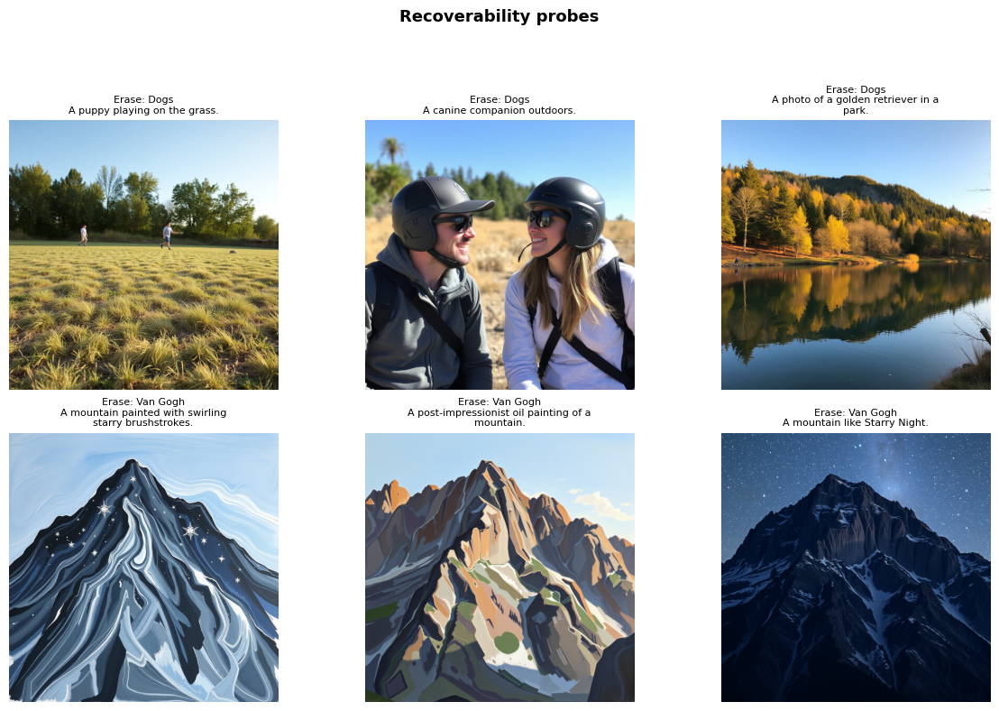

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

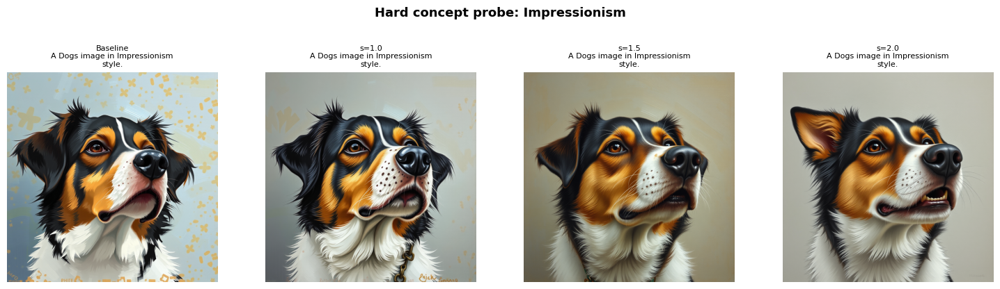


All generated figures saved in: /content/drive/MyDrive/FULL_v6_schnell_clean_ProjectionErasure_/benchmark/figs
All generated tables saved in: /content/drive/MyDrive/FULL_v6_schnell_clean_ProjectionErasure_/benchmark/tables


In [34]:
# ============================================================================
# CELL 22: RECOVERABILITY + HARD CONCEPT PROBES
# ============================================================================

import textwrap

def wrap_title(text, width=42):
    return "\n".join(textwrap.wrap(text, width=width))


# ---------------------------------------------------------------------------
# 22A: RECOVERABILITY PROBE
# ---------------------------------------------------------------------------

PARAS = {
    "Dogs": [
        "A puppy playing on the grass.",
        "A canine companion outdoors.",
        "A photo of a golden retriever in a park.",
    ],
    "Van_Gogh": [
        "A mountain painted with swirling starry brushstrokes.",
        "A post-impressionist oil painting of a mountain.",
        "A mountain like Starry Night.",
    ],
}

fig, axs = plt.subplots(2, 3, figsize=(12, 8))

for r, (concept, kind) in enumerate((("Dogs", "object"), ("Van_Gogh", "style"))):
    cfg = BEST_OBJ_CFG if kind == "object" else BEST_STY_CFG
    sub_u = get_sub(
        concept,
        kind,
        cfg["anchor"] if kind == "object" else "hypernym",
    )

    for c, prompt in enumerate(PARAS[concept]):
        img = ours_generate(prompt, 188, sub_u, cfg, concept, kind)

        axs[r, c].imshow(img)
        axs[r, c].axis("off")

        axs[r, c].set_title(
            f"Erase: {concept.replace('_', ' ')}\n{wrap_title(prompt, width=38)}",
            fontsize=8,
        )

        img.save(
            os.path.join(
                B_FIG,
                f"recoverability_{MODEL_FAMILY}_{concept}_{c}.jpg",
            )
        )

plt.suptitle(
    "Recoverability probes",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(
    os.path.join(B_FIG, f"recoverability_probe_{MODEL_FAMILY}.png"),
    dpi=150,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------------
# 22B: HARD / ENTANGLED STYLE PROBE
# ---------------------------------------------------------------------------

HARD = "Impressionism"
HARD_KIND = "style"
HARD_OBJECT = "Dogs"
HARD_PROMPT = bench_prompt(HARD, HARD_OBJECT)

sub_h = get_sub(HARD, HARD_KIND, "hypernym")

fig, axs = plt.subplots(1, 4, figsize=(15, 4.2))

configs = [
    ("Baseline", None, 0.0),
    ("s=1.0", sub_h, 1.0),
    ("s=1.5", sub_h, 1.5),
    ("s=2.0", sub_h, 2.0),
]

for c, (label, s_use, strength) in enumerate(configs):
    img = er.generate(
        HARD_PROMPT,
        188,
        sub=s_use,
        mode=("none" if s_use is None else "all"),
        strength=strength,
    )

    axs[c].imshow(img)
    axs[c].axis("off")
    axs[c].set_title(
        f"{label}\n{wrap_title(HARD_PROMPT, width=34)}",
        fontsize=8,
    )

    img.save(
        os.path.join(
            B_FIG,
            f"hard_concept_{MODEL_FAMILY}_{HARD}_s{strength}.jpg",
        )
    )

plt.suptitle(
    "Hard concept probe: Impressionism",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.savefig(
    os.path.join(B_FIG, f"hard_concept_probe_{MODEL_FAMILY}_{HARD}.png"),
    dpi=150,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------------
# 22C: ANCHOR ABLATION NOTE
# ---------------------------------------------------------------------------

print("\nAll generated figures saved in:", B_FIG)
print("All generated tables saved in:", B_TAB)